# Физическое моделирование жидкосцинтилляционного детектора
## Домашнее задание № 1 — задачи 1–10

Ноутбук содержит десять последовательно расположенных решений. Каждая задача начинается с отдельного заголовка; ниже приведены относящиеся к ней пояснения, программная реализация, проверки и результаты моделирования.

**Порядок выполнения:**
1. Создание детектора (`Detector`).
2. Создание источника фотонов (`Source`).
3. Распространение и детектирование света (`intersect_sphere`, `Photomultiplier`, `simulate_event`).
4. Энергетический отклик детектора (`simulate_charge_ensemble`).
5. Пуассоновский источник и потоковая генерация фотонов (`SmartSource`).
6. Экспоненциальное затухание света и сравнение энергетического отклика.
7. Векторизация вычислений и сравнение с циклом Python.
8. Большой детектор и ускоренный поиск ФЭУ через `cKDTree`.
9. MCMC-моделирование изотропных направлений и сравнение отклика с задачей 4.

**Важно:** для корректной работы выполните ячейки последовательно сверху вниз. Пакет `k3d` используется для интерактивной 3D-визуализации, в том числе для события из задачи 5.

В ноутбуке также представлены решения задач 7–9: векторизация вычислений, ускоренный поиск ФЭУ и MCMC-моделирование отклика.

# ЗАДАЧА 1. СОЗДАНИЕ ДЕТЕКТОРА

**Что решается в этом разделе:** создаётся класс `Detector`, задающий сферическую геометрию детектора и расположение фотоумножителей на его поверхности.

**Параметры из условия:**
- радиус детектора: `R = 2 м`;
- число фотоумножителей: `N = 40`;
- радиус фотокатода: `r = 0.10 м` (10 см);
- параметр `a = 0.5` — используется в модели как коэффициент визуального выноса ФЭУ над поверхностью.

Фотоумножители распределяются по сфере достаточно равномерно с помощью спирали Фибоначчи. Координаты и направления ФЭУ сохраняются в объекте `Detector`.

**Результат задачи:** готовый объект `detector`, содержащий геометрию сферического детектора и координаты всех фотоумножителей.

## 1. Геометрия детектора из предыдущей задачи

Сохраняем модель сферического детектора и расположение фотоумножителей из предоставленного ноутбука предыдущей задачи. Это позволяет далее использовать общий проект в одном окружении. Для решения задачи 2 наличие `k3d` необязательно: библиотека нужна только для интерактивной 3D-визуализации геометрии.

**Зависимости:** `numpy`, `matplotlib`, `k3d`. Для интерактивной 3D-визуализации обязательно установите K3D, если он отсутствует: `%pip install k3d`. После установки перезапустите ядро и выполните ноутбук сверху вниз.

In [1]:
%pip install k3d

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\Public\Documents\Макар 07_10_2026 22_57\Учёба\ФНАФЧ\Коды\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
# ==================== ЗАДАЧА 1: КЛАСС DETECTOR ====================
"""
Detector: сферический детектор с N фотоумножителями.

Параметры по умолчанию:
    R = 2.0 м   — радиус поверхности детектора
    N = 40      — число фотоумножителей
    r = 0.10 м  — радиус одного фотоумножителя (10 см)
    a = 0.5     — коэффициент подъёма при визуализации (чтобы ФЭУ были видны над сферой)

Расположение ФЭУ — по спирали Фибоначчи (равномерно по сфере).
"""

import numpy as np

try:
    import k3d
except ImportError:
    k3d = None


# ---------- вспомогательные функции ----------

def _uv_sphere(R, n_u=72, n_v=36):
    """Сетка UV-сферы: возвращает (vertices, indices)."""
    u = np.linspace(0.0, 2.0 * np.pi, n_u, endpoint=False)
    v = np.linspace(0.0, np.pi, n_v)
    U, V = np.meshgrid(u, v)
    X = R * np.sin(V) * np.cos(U)
    Y = R * np.sin(V) * np.sin(U)
    Z = R * np.cos(V)
    verts = np.stack([X, Y, Z], axis=-1).reshape(-1, 3).astype(np.float32)

    idx = []
    for i in range(n_v - 1):
        for j in range(n_u):
            j2 = (j + 1) % n_u
            a = i * n_u + j
            b = i * n_u + j2
            c = (i + 1) * n_u + j
            d = (i + 1) * n_u + j2
            idx.append([a, c, b])
            idx.append([b, c, d])
    return verts, np.asarray(idx, dtype=np.uint32)


def _cap_mesh(direction, R, theta, n=24):
    """
    Сферическая «шапочка» радиуса R с угловым полураствором theta
    вокруг направления direction. Возвращает (vertices, indices).
    """
    d = direction / np.linalg.norm(direction)
    tmp = np.array([1.0, 0.0, 0.0])
    if abs(np.dot(d, tmp)) > 0.9:
        tmp = np.array([0.0, 1.0, 0.0])
    e1 = np.cross(d, tmp); e1 /= np.linalg.norm(e1)
    e2 = np.cross(d, e1)

    verts = [R * d]
    for phi in np.linspace(0.0, 2.0 * np.pi, n, endpoint=False):
        p = (R * np.cos(theta) * d
             + R * np.sin(theta) * (np.cos(phi) * e1 + np.sin(phi) * e2))
        verts.append(p)
    verts = np.asarray(verts, dtype=np.float32)

    idx = []
    for i in range(1, n + 1):
        j = i + 1 if i < n else 1
        idx.append([0, i, j])
    return verts, np.asarray(idx, dtype=np.uint32)


# ---------- основной класс ----------

class Detector:
    def __init__(self, R=2.0, N=40, r=0.10, a=0.5):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r)
        self.a = float(a)

        # Угловой радиус одной «шапочки» ФЭУ, видимой из центра сферы
        self.theta_pmt = float(np.arcsin(self.r / self.R))

        # Равномерное расположение ФЭУ (спираль Фибоначчи)
        self.pmt_directions = self._fibonacci_sphere(self.N)      # (N, 3) — единичные векторы
        self.pmt_centers = self.pmt_directions * self.R            # (N, 3) — центры на сфере

        # Структура для хранения информации о каждом ФЭУ
        self.pmts = [
            {
                "id": i,
                "direction": self.pmt_directions[i],
                "center": self.pmt_centers[i],
                "radius": self.r,
                "theta": self.theta_pmt,
            }
            for i in range(self.N)
        ]

    # ---- генерация точек ----
    @staticmethod
    def _fibonacci_sphere(N):
        idx = np.arange(N, dtype=float)
        phi = np.pi * (3.0 - np.sqrt(5.0))     # золотой угол
        y = 1.0 - 2.0 * (idx + 0.5) / N
        r_xy = np.sqrt(np.clip(1.0 - y * y, 0.0, 1.0))
        theta = phi * idx
        x = np.cos(theta) * r_xy
        z = np.sin(theta) * r_xy
        return np.stack([x, y, z], axis=1)

    # ---- геометрическая проверка ----
    def belongs_to_pmt(self, point):
        """
        Принадлежит ли точка (x, y, z) поверхности какому-либо ФЭУ?
        Возвращает id ФЭУ или None.
        """
        p = np.asarray(point, dtype=float)
        norm = np.linalg.norm(p)
        if norm == 0.0:
            return None
        p_dir = p / norm
        cos_ang = self.pmt_directions @ p_dir                # (N,)
        angles = np.arccos(np.clip(cos_ang, -1.0, 1.0))
        k = int(np.argmin(angles))
        return k if angles[k] <= self.theta_pmt else None

    # ---- визуализация ----
    def build_plot(self, sphere_color=0x3050a0, pmt_color=0xffcc00):
        if k3d is None:
            raise ImportError(
                "Для 3D-визуализации установите k3d: %pip install k3d"
            )
        plot = k3d.plot(name="Detector")

        # 1) Поверхность детектора (полупрозрачная сфера)
        verts, indices = _uv_sphere(self.R)
        plot += k3d.mesh(verts, indices,
                         color=sphere_color, opacity=0.15,
                         wireframe=False)

        # 2) Фотоумножители — единый меш из сферических «шапочек»
        all_v, all_i = [], []
        offset = 0
        for pmt in self.pmts:
            v, i = _cap_mesh(pmt["direction"],
                             self.R + self.a * self.r,   # слегка приподняты для наглядности
                             self.theta_pmt,
                             n=24)
            all_v.append(v)
            all_i.append(i + offset)
            offset += len(v)

        plot += k3d.mesh(np.vstack(all_v), np.vstack(all_i),
                         color=pmt_color, wireframe=False)
        return plot

In [3]:
import matplotlib.pyplot as plt


### Проверка геометрии детектора (необязательный блок)

Если пакет `k3d` установлен, следующая ячейка построит 3D-модель. В противном случае код сообщит, как установить пакет; расчёты источника от него не зависят.

In [4]:
detector = Detector(R=2.0, N=40, r=0.10, a=0.5)

print(f"Радиус детектора: {detector.R:.2f} м")
print(f"Количество фотоумножителей: {detector.N}")
print(f"Радиус фотокатода: {detector.r:.2f} м")
print(f"Угловой радиус фотокатода: {detector.theta_pmt:.5f} рад")

if k3d is not None:
    detector_plot = detector.build_plot()
    detector_plot
else:
    print("3D-визуализация пропущена: установите k3d командой %pip install k3d.")

Радиус детектора: 2.00 м
Количество фотоумножителей: 40
Радиус фотокатода: 0.10 м
Угловой радиус фотокатода: 0.05002 рад


# ЗАДАЧА 2. СОЗДАНИЕ ИСТОЧНИКА ФОТОНОВ

В этом ноутбуке реализован программный источник сцинтилляционных фотонов. Он принимает энергию события $E$, рассчитывает число фотонов по заданному световыходу и генерирует начальные направления их движения.

**Параметр из условия:**
$$
Y=10\,000\ \frac{\text{фотонов}}{\text{МэВ}}.
$$

**Физические допущения задачи:**
1. Излучение изотропно.
2. Средний выход фотонов линейно зависит от энергии:
   $$
N_\gamma = YE.
$$

В рамках этой задачи моделируются только начальные направления фотонов. Перенос фотонов в жидкости, поглощение, рассеяние и регистрация фотоумножителями относятся к следующим этапам моделирования.

## 2. Физическая модель источника

### 2.1. Число фотонов

Для события с энергией $E$ (в МэВ) число испускаемых фотонов задаётся линейным законом:
$$
N_\gamma = YE.
$$

Поскольку число фотонов — целое, в основном режиме используется округление до ближайшего целого:
$$
N_\gamma = \operatorname{round}(YE).
$$

Например, для $E=1$ МэВ источник генерирует 10 000 фотонов.

### 2.2. Изотропное распределение направлений

Направление фотона зададим сферическими углами $\theta$ и $\varphi$:
$$
\begin{aligned}
n_x &= \sin\theta\cos\varphi,\\
n_y &= \sin\theta\sin\varphi,\\
n_z &= \cos\theta.
\end{aligned}
$$

Для равномерного распределения по телесному углу необходимо разыгрывать:
$$
\varphi\sim U(0,2\pi),\qquad
\mu=\cos\theta\sim U(-1,1).
$$

**Ключевой момент:** полярный угол $\theta$ нельзя разыгрывать равномерно. При изотропном излучении равномерно распределён именно $\cos\theta$. Такой выбор обеспечивает постоянную вероятность попадания в равные телесные углы.

## 3. Реализация класса `Source`

Класс разделяет две операции: определение числа фотонов и генерацию их направлений. Все направления возвращаются в виде единичных декартовых векторов. Генератор случайных чисел можно передать извне для воспроизводимости результатов.

In [5]:
# ==================== ЗАДАЧА 2: КЛАСС SOURCE ====================
from typing import Optional

YIELD_PER_MEV = 10_000


class Source:
    """Источник изотропного сцинтилляционного излучения.

    Parameters
    ----------
    Y : float
        Световыход в фотонах/МэВ.

    Methods
    -------
    photon_count(E)
        Возвращает число фотонов для энергии E (МэВ).
    generate_directions(E, rng=None)
        Генерирует массив единичных направлений формы (N_gamma, 3).
    """

    def __init__(self, Y: float = YIELD_PER_MEV) -> None:
        if not np.isfinite(Y) or Y <= 0:
            raise ValueError("Y должен быть конечным положительным числом.")
        self.Y = float(Y)

    def photon_count(self, E: float) -> int:
        """Число фотонов по линейному закону N_gamma = Y * E."""
        if not np.isfinite(E) or E < 0:
            raise ValueError("Энергия E должна быть конечной и неотрицательной.")
        return int(np.rint(self.Y * float(E)))

    def generate_directions(
        self,
        E: float,
        rng: Optional[np.random.Generator] = None,
    ) -> np.ndarray:
        """Сгенерировать изотропные начальные направления фотонов.

        Parameters
        ----------
        E : float
            Энергия события в МэВ.
        rng : numpy.random.Generator, optional
            Генератор случайных чисел. При отсутствии создаётся новый.

        Returns
        -------
        numpy.ndarray
            Массив формы (N_gamma, 3). Каждая строка — единичный
            вектор направления (n_x, n_y, n_z).
        """
        rng = np.random.default_rng() if rng is None else rng
        n_photons = self.photon_count(E)

        # Изотропность на сфере: phi равномерно на [0, 2*pi),
        # cos(theta) равномерно на [-1, 1].
        phi = rng.uniform(0.0, 2.0 * np.pi, size=n_photons)
        cos_theta = rng.uniform(-1.0, 1.0, size=n_photons)
        sin_theta = np.sqrt(np.maximum(0.0, 1.0 - cos_theta**2))

        directions = np.column_stack((
            sin_theta * np.cos(phi),
            sin_theta * np.sin(phi),
            cos_theta,
        ))
        return directions


## 4. Пример использования

Рассмотрим событие с энергией 1 МэВ. Зафиксируем `seed`, чтобы при повторном запуске получить те же направления.

In [6]:
source = Source(Y=10_000)
rng = np.random.default_rng(seed=2026)

energy = 1.0  # МэВ
directions = source.generate_directions(energy, rng=rng)

print(f"Энергия события:       {energy:.3f} МэВ")
print(f"Световыход:            {source.Y:,.0f} фотонов/МэВ")
print(f"Число фотонов:         {len(directions):,}")
print(f"Размер массива:        {directions.shape}")
print(f"Первые пять направлений:\n{directions[:5]}")

Энергия события:       1.000 МэВ
Световыход:            10,000 фотонов/МэВ
Число фотонов:         10,000
Размер массива:        (10000, 3)
Первые пять направлений:
[[ 0.23106289  0.48262279  0.8447989 ]
 [-0.506212   -0.6112259   0.60840144]
 [-0.97848324  0.20411952  0.03009613]
 [-0.62890714  0.66551143  0.40195813]
 [-0.38579199  0.49789382 -0.77670219]]


## 5. Численная верификация

Проверим три свойства реализации:
- число фотонов соответствует заданному линейному закону;
- каждое направление имеет единичную длину;
- при изотропном распределении средние компоненты направлений близки к нулю.

In [7]:
# 1. Проверка количества фотонов
expected_count = int(round(source.Y * energy))
assert directions.shape == (expected_count, 3)

# 2. Проверка единичной длины всех векторов
norms = np.linalg.norm(directions, axis=1)
assert np.allclose(norms, 1.0, atol=1e-12)

# 3. Для изотропного распределения среднее направление должно быть около нуля
mean_direction = directions.mean(axis=0)

print(f"Ожидаемое число фотонов: {expected_count:,}")
print(f"Фактическое число фотонов: {len(directions):,}")
print(f"Максимальное отклонение нормы от 1: {np.max(np.abs(norms - 1)):.3e}")
print(f"Средний вектор направлений: {mean_direction}")

assert np.all(np.abs(mean_direction) < 0.03)
print("\nВсе проверки успешно пройдены.")

Ожидаемое число фотонов: 10,000
Фактическое число фотонов: 10,000
Максимальное отклонение нормы от 1: 2.220e-16
Средний вектор направлений: [-0.00425032 -0.00413056 -0.0056235 ]

Все проверки успешно пройдены.


## 6. Проверка изотропности распределения

Для изотропного источника величины $\cos\theta$ и $\varphi$ равномерны на интервалах $[-1,1]$ и $[0,2\pi)$ соответственно. Гистограммы сравниваются с теоретическими плотностями.

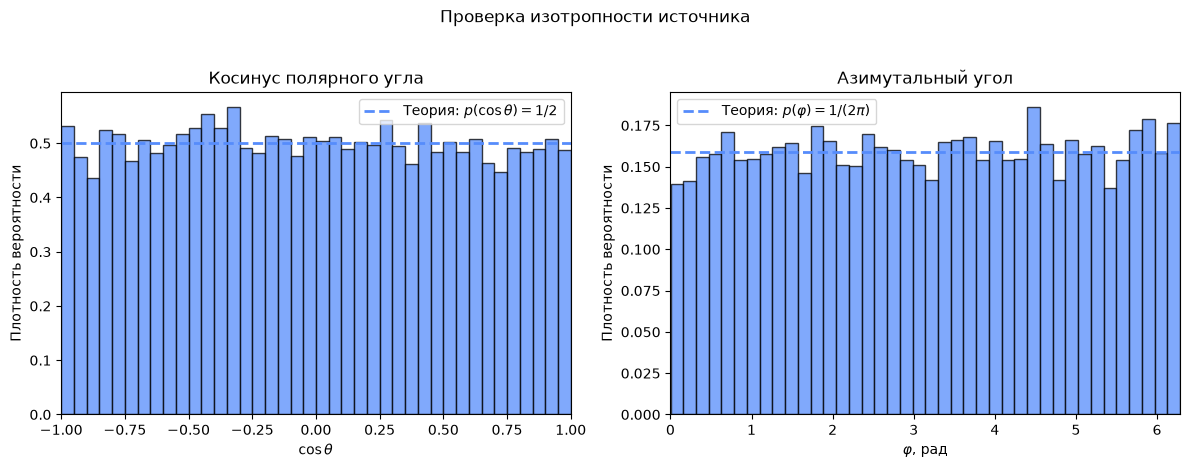

In [8]:
cos_theta = directions[:, 2]
phi = np.mod(np.arctan2(directions[:, 1], directions[:, 0]), 2 * np.pi)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(cos_theta, bins=40, density=True, alpha=0.75, edgecolor="black")
axes[0].axhline(0.5, linestyle="--", linewidth=2,
                label=r"Теория: $p(\cos\theta)=1/2$")
axes[0].set(
    xlabel=r"$\cos\theta$",
    ylabel="Плотность вероятности",
    title="Косинус полярного угла",
    xlim=(-1, 1),
)
axes[0].legend()

axes[1].hist(phi, bins=40, density=True, alpha=0.75, edgecolor="black")
axes[1].axhline(1 / (2 * np.pi), linestyle="--", linewidth=2,
                label=r"Теория: $p(\varphi)=1/(2\pi)$")
axes[1].set(
    xlabel=r"$\varphi$, рад",
    ylabel="Плотность вероятности",
    title="Азимутальный угол",
    xlim=(0, 2 * np.pi),
)
axes[1].legend()

fig.suptitle("Проверка изотропности источника", y=1.03)
plt.tight_layout()
plt.show()

## 7. Зависимость выхода фотонов от энергии

Проверим линейный закон для нескольких энергий. Это тест детерминированной модели, в которой число фотонов округляется до целого.

E =  0.1 МэВ -> N_gamma =   1,000
E =  0.5 МэВ -> N_gamma =   5,000
E =  1.0 МэВ -> N_gamma =  10,000
E =  2.0 МэВ -> N_gamma =  20,000
E =  5.0 МэВ -> N_gamma =  50,000


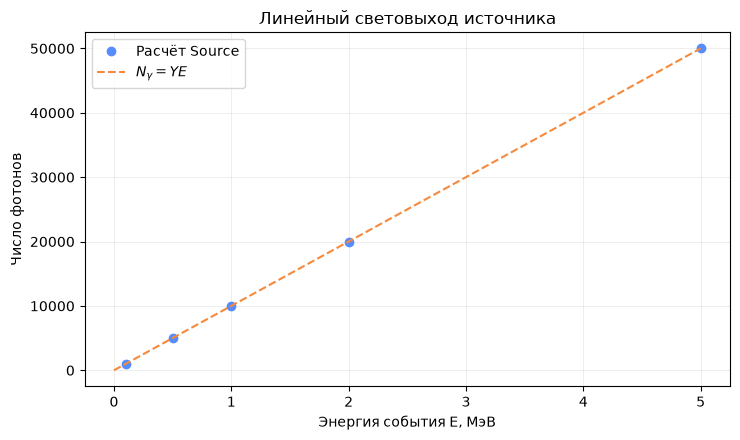

In [9]:
energies = np.array([0.1, 0.5, 1.0, 2.0, 5.0])
counts = np.array([source.photon_count(E) for E in energies])

for E, count in zip(energies, counts):
    print(f"E = {E:4.1f} МэВ -> N_gamma = {count:>7,d}")

energy_grid = np.linspace(0.0, energies.max(), 200)
plt.figure(figsize=(7.5, 4.5))
plt.plot(energies, counts, "o", label="Расчёт Source")
plt.plot(energy_grid, source.Y * energy_grid, "--", label=r"$N_\gamma=YE$")
plt.xlabel("Энергия события E, МэВ")
plt.ylabel("Число фотонов")
plt.title("Линейный световыход источника")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Итог

Реализован класс `Source` со световыходом $Y=10\,000$ фотонов/МэВ.

Для заданной энергии $E$ метод `generate_directions`:
1. рассчитывает число фотонов $N_\gamma=\operatorname{round}(YE)$;
2. генерирует для каждого фотона изотропное направление;
3. возвращает массив единичных векторов $(n_x,n_y,n_z)$.

Изотропность обеспечивается равномерной генерацией азимутального угла $\varphi$ и косинуса полярного угла $\cos\theta$. Численные тесты проверяют размер массива, нормировку направлений и статистическую симметрию распределения.

**Границы модели:** в соответствии с формулировкой задачи источник задаёт только начальные направления фотонов. Время испускания, координаты рождения, спектр длин волн, перенос света, отражение, поглощение и отклик фотоумножителей здесь не моделируются.

# ЗАДАЧА 3. РАСПРОСТРАНЕНИЕ И ДЕТЕКТИРОВАНИЕ СВЕТА

**Что решается в этом разделе:** моделируется движение фотонов от точки рождения до сферической поверхности детектора и проверяется, попадает ли фотон на фотокатод одного из ФЭУ.

Основные этапы:
1. Вычисление точки первого пересечения траектории фотона со сферой.
2. Определение фотоумножителя, покрывающего точку попадания.
3. Генерация числа фотоэлектронов по распределению Пуассона.
4. Расчёт полного собранного заряда и распределения сигнала по каналам.
5. Визуализация траекторий и геометрии в K3D.

**Результат задачи:** функция моделирования одного события `simulate_event`, статистика регистрации и 3D-визуализация.

# Задача 3. Распространение и детектирование света

В этой части используется геометрия детектора и источник фотонов, реализованные выше.

Для каждого фотона:
1. задаётся точка рождения $\mathbf{x}_0=(x,y,z)$ и единичное направление $\mathbf{n}=(n_x,n_y,n_z)$;
2. вычисляется пересечение луча со сферической границей радиуса $R$;
3. определяется, попала ли точка пересечения на фотокатод одного из ФЭУ;
4. если фотон попал на фотокатод, число фотоэлектронов разыгрывается из распределения Пуассона со средним $a$.

Упрощения строго соответствуют условию: рассеянием и поглощением в жидкости пренебрегаем; фотон полностью поглощается при достижении границы. Отражённые и повторно испущенные фотоны не рассматриваются.

## 9. Геометрия пересечения луча со сферой

Траектория фотона:
$$
\mathbf{x}(t)=\mathbf{x}_0+t\mathbf{n},\qquad t\geq0.
$$
На границе сферы $|\mathbf{x}(t)|=R$. Решение квадратного уравнения:
$$
t=-\mathbf{x}_0\cdot\mathbf{n}
+\sqrt{(\mathbf{x}_0\cdot\mathbf{n})^2+R^2-|\mathbf{x}_0|^2}.
$$
Берём положительный корень, соответствующий первому пересечению границы в направлении движения. Точка попадания равна $\mathbf{x}_{hit}=\mathbf{x}_0+t\mathbf{n}$.

Для определения ФЭУ используем сферические фотокатоды из модели детектора: фотон попадает на ФЭУ, если угол между направлением на точку попадания и осью фотокатода не превышает `detector.theta_pmt`. Если ни один фотокатод не покрывает эту точку, фотон считается не зарегистрированным.

In [10]:
# ==================== ЗАДАЧА 3: ПЕРЕСЕЧЕНИЕ СФЕРЫ ====================
def intersect_sphere(
    origin: np.ndarray,
    direction: np.ndarray,
    radius: float,
) -> tuple[float, np.ndarray]:
    """Первое пересечение луча с поверхностью сферы с центром в начале координат.

    Parameters
    ----------
    origin : array-like, shape (3,)
        Точка рождения фотона внутри сферы.
    direction : array-like, shape (3,)
        Направление движения фотона (нормируется внутри функции).
    radius : float
        Радиус сферы.

    Returns
    -------
    distance : float
        Путь от origin до границы.
    hit_point : ndarray, shape (3,)
        Координаты точки пересечения.
    """
    origin = np.asarray(origin, dtype=float)
    direction = np.asarray(direction, dtype=float)

    if origin.shape != (3,) or direction.shape != (3,):
        raise ValueError("origin и direction должны быть векторами длины 3.")
    if not np.all(np.isfinite(origin)) or not np.all(np.isfinite(direction)):
        raise ValueError("Координаты и направление должны быть конечными.")
    if not np.isfinite(radius) or radius <= 0:
        raise ValueError("Радиус сферы должен быть положительным.")
    if np.linalg.norm(origin) >= radius:
        raise ValueError("Источник должен находиться строго внутри детектора.")

    norm = np.linalg.norm(direction)
    if norm == 0:
        raise ValueError("Нулевое направление фотона недопустимо.")
    n = direction / norm

    projection = float(np.dot(origin, n))
    discriminant = projection**2 + radius**2 - float(np.dot(origin, origin))
    distance = -projection + np.sqrt(max(discriminant, 0.0))
    hit_point = origin + distance * n
    return float(distance), hit_point


def find_pmt_at_hit(detector: Detector, hit_point: np.ndarray):
    """Вернуть индекс ФЭУ, покрывающего точку попадания, или None."""
    hit_point = np.asarray(hit_point, dtype=float)
    if hit_point.shape != (3,) or np.linalg.norm(hit_point) == 0:
        raise ValueError("Некорректная точка попадания.")
    hit_direction = hit_point / np.linalg.norm(hit_point)
    cos_angles = detector.pmt_directions @ hit_direction
    # Сравнение через cos избегает вычисления arccos для всех ФЭУ.
    threshold = np.cos(detector.theta_pmt)
    pmt_index = int(np.argmax(cos_angles))
    return pmt_index if cos_angles[pmt_index] >= threshold else None


## 10. Модель фотоумножителя и статистика фотоэлектронов

Число фотоэлектронов при попадании фотона на фотокатод задано распределением Пуассона:
$$
N_{pe}\sim\operatorname{Poisson}(a),\qquad
P(N_{pe}=k)=\frac{a^k e^{-a}}{k!}.
$$

Метод генерации фотоэлектронов логично относится к классу `Photomultiplier`, а не к `Source` или `Detector`: это отклик конкретного фотокатода на попавший на него фотон. Геометрический поиск фотокатода остаётся ответственностью `Detector`.

In [11]:
class Photomultiplier:
    """Модель отклика одного фотокатода на попавший фотон."""

    def __init__(self, mean_photoelectrons: float, pmt_id: int) -> None:
        if not np.isfinite(mean_photoelectrons) or mean_photoelectrons < 0:
            raise ValueError("Среднее число фотоэлектронов a должно быть >= 0.")
        self.mean_photoelectrons = float(mean_photoelectrons)
        self.pmt_id = int(pmt_id)

    def generate_photoelectrons(
        self,
        rng: np.random.Generator,
    ) -> int:
        """Разыграть число фотоэлектронов из Poisson(a)."""
        return int(rng.poisson(self.mean_photoelectrons))


## 11. Полное моделирование одного события

Функция ниже моделирует все фотоны события, распределяет фотоэлектроны по каналам ФЭУ и сохраняет геометрию траекторий для последующей визуализации. Фотоэлектроны генерируются только для фотонов, попавших на фотокатод.

In [12]:
def simulate_event(
    detector: Detector,
    source: Source,
    energy_mev: float,
    origin=(0.0, 0.0, 0.0),
    a: float = 0.5,
    seed: int = 2026,
):
    """Полный цикл: источник -> пересечение сферы -> ФЭУ -> фотоэлектроны."""
    origin = np.asarray(origin, dtype=float)
    if origin.shape != (3,) or not np.all(np.isfinite(origin)):
        raise ValueError("origin должен быть конечным вектором длины 3.")
    if np.linalg.norm(origin) >= detector.R:
        raise ValueError("Источник должен находиться внутри детектора.")

    rng = np.random.default_rng(seed)
    directions = source.generate_directions(energy_mev, rng=rng)
    n_photons = len(directions)

    pmt_models = [
        Photomultiplier(mean_photoelectrons=a, pmt_id=i)
        for i in range(detector.N)
    ]

    hit_points = np.empty((n_photons, 3), dtype=float)
    path_lengths = np.empty(n_photons, dtype=float)
    pmt_indices = np.full(n_photons, -1, dtype=int)
    photoelectrons = np.zeros(n_photons, dtype=int)
    pmt_counts = np.zeros(detector.N, dtype=int)

    for i, direction in enumerate(directions):
        distance, point = intersect_sphere(origin, direction, detector.R)
        path_lengths[i] = distance
        hit_points[i] = point

        pmt_id = find_pmt_at_hit(detector, point)
        if pmt_id is not None:
            pmt_indices[i] = pmt_id
            npe = pmt_models[pmt_id].generate_photoelectrons(rng)
            photoelectrons[i] = npe
            pmt_counts[pmt_id] += npe

    return {
        "origin": origin,
        "directions": directions,
        "hit_points": hit_points,
        "path_lengths": path_lengths,
        "pmt_indices": pmt_indices,
        "photoelectrons": photoelectrons,
        "pmt_counts": pmt_counts,
        "total_photoelectrons": int(photoelectrons.sum()),
        "detected_photons": int(np.count_nonzero(pmt_indices >= 0)),
        "n_photons": n_photons,
    }


## 12. Запуск моделирования: событие 1 МэВ в центре

Используем параметры детектора, заданные выше (`R=2 м`, `N=40`, `r=0.10 м`), и среднее число фотоэлектронов `a=0.5` на один попавший фотон. Фиксированный seed обеспечивает воспроизводимый пример.

In [13]:
EVENT_ENERGY_MEV = 1.0
PHOTOELECTRON_MEAN = 0.5
EVENT_ORIGIN = (0.0, 0.0, 0.0)

event = simulate_event(
    detector=detector,
    source=source,
    energy_mev=EVENT_ENERGY_MEV,
    origin=EVENT_ORIGIN,
    a=PHOTOELECTRON_MEAN,
    seed=2026,
)

print(f"Энергия события:                  {EVENT_ENERGY_MEV:.2f} МэВ")
print(f"Испущено фотонов:                 {event['n_photons']:,}")
print(f"Фотонов, попавших на фотокатоды:   {event['detected_photons']:,}")
print(f"Геометрическая эффективность:     {event['detected_photons']/event['n_photons']:.4%}")
print(f"Полное число фотоэлектронов:       {event['total_photoelectrons']:,}")
print(f"Среднее число фотоэлектронов/ФЭУ:  {event['pmt_counts'].mean():.3f}")
print(f"Максимум на одном ФЭУ:             {event['pmt_counts'].max()}")

Энергия события:                  1.00 МэВ
Испущено фотонов:                 10,000
Фотонов, попавших на фотокатоды:   237
Геометрическая эффективность:     2.3700%
Полное число фотоэлектронов:       107
Среднее число фотоэлектронов/ФЭУ:  2.675
Максимум на одном ФЭУ:             8


## 13. Сравнение с ожидаемым полным зарядом

В условии предложено сравнить результат с выражением
$$
Q_{given}=aY\frac{Nr^2}{R^2}.
$$
Здесь $Q$ измеряется в фотоэлектронах (при единичном заряде одного фотоэлектрона).

В данной геометрической реализации фотокатоды — сферические шапочки с угловым радиусом $\theta=\arcsin(r/R)$. Их точная доля телесного угла для одного ФЭУ:
$$
f_1=\frac{1-\cos\theta}{2}.
$$
Для неперекрывающихся одинаковых ФЭУ ожидаемое число фотоэлектронов:
$$
Q_{geom}=aYE\,Nf_1.
$$
При $r\ll R$:
$$
Q_{geom}\simeq aYE\frac{Nr^2}{4R^2}.
$$

**Обратите внимание:** в записанной в условии формуле $Q_{given}$ отсутствует множитель $1/4$, который следует из отношения площади фотокатодов к площади сферы $4\pi R^2$. Поэтому ниже приводятся оба значения: буквальная формула из задания и оценка, соответствующая реализованной геометрии. Это позволяет увидеть и объяснить возможное расхождение, а не подгонять симуляцию под формулу.

In [14]:
theta = detector.theta_pmt
solid_angle_fraction_one = (1.0 - np.cos(theta)) / 2.0
geometric_coverage = detector.N * solid_angle_fraction_one

q_given = (
    PHOTOELECTRON_MEAN * source.Y * EVENT_ENERGY_MEV
    * detector.N * detector.r**2 / detector.R**2
)
q_geometry = (
    PHOTOELECTRON_MEAN * source.Y * EVENT_ENERGY_MEV
    * geometric_coverage
)
q_small_angle = (
    PHOTOELECTRON_MEAN * source.Y * EVENT_ENERGY_MEV
    * detector.N * detector.r**2 / (4.0 * detector.R**2)
)

print(f"Q по формуле, записанной в условии:     {q_given:.2f} p.e.")
print(f"Q по точной геометрии сферических шапочек: {q_geometry:.2f} p.e.")
print(f"Q по приближению r << R:                 {q_small_angle:.2f} p.e.")
print(f"Результат моделирования:                 {event['total_photoelectrons']} p.e.")
print(f"Отклонение от Q_geometry:                "
      f"{(event['total_photoelectrons']-q_geometry)/q_geometry:.2%}")

print("\\nПараметры модели:")
print(f"Суммарная доля покрытия сферы: {geometric_coverage:.4%}")
print(f"Ожидаемое число попавших фотонов: "
      f"{event['n_photons'] * geometric_coverage:.2f}")

Q по формуле, записанной в условии:     500.00 p.e.
Q по точной геометрии сферических шапочек: 125.08 p.e.
Q по приближению r << R:                 125.00 p.e.
Результат моделирования:                 107 p.e.
Отклонение от Q_geometry:                -14.45%
\nПараметры модели:
Суммарная доля покрытия сферы: 2.5016%
Ожидаемое число попавших фотонов: 250.16


## 14. Распределение фотоэлектронов по каналам ФЭУ

Покажем вклад каждого канала и распределение точек попадания на поверхность.

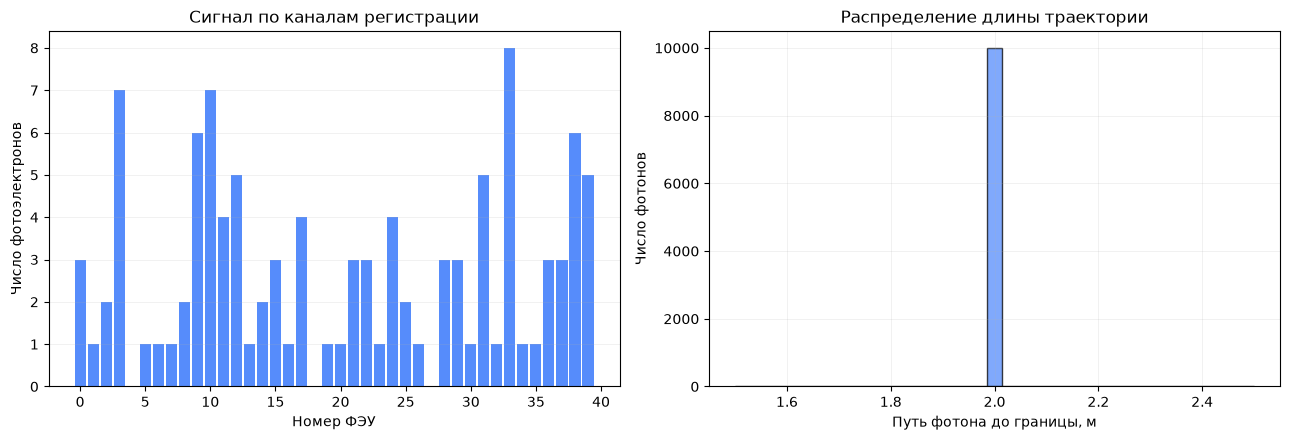

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(np.arange(detector.N), event["pmt_counts"], width=0.85)
axes[0].set(
    xlabel="Номер ФЭУ",
    ylabel="Число фотоэлектронов",
    title="Сигнал по каналам регистрации",
)
axes[0].grid(axis="y", alpha=0.25)

axes[1].hist(event["path_lengths"], bins=35, edgecolor="black", alpha=0.75)
axes[1].set(
    xlabel="Путь фотона до границы, м",
    ylabel="Число фотонов",
    title="Распределение длины траектории",
)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 15. Обязательная 3D-визуализация детектора в K3D

На интерактивной сцене отображаются:
- полупрозрачная сферическая граница детектора;
- все фотокатоды;
- точка рождения события;
- выборка траекторий фотонов: зелёные линии заканчиваются на ФЭУ, красные — на непокрытой части поверхности;
- точки попадания выбранных фотонов.

Для читаемости показывается ограниченная случайная выборка траекторий, но статистика и полный заряд выше рассчитаны по **всем** фотонам события. Если `k3d` ещё не установлен, выполните `%pip install k3d`, затем перезапустите kernel и ячейки ноутбука.

In [16]:
# K3D обязателен для выполнения визуализационной части задачи.
try:
    import k3d
except ImportError as exc:
    raise ImportError(
        "Для обязательной 3D-визуализации установите K3D: %pip install k3d, "
        "затем перезапустите kernel."
    ) from exc


def visualize_event_k3d(
    detector: Detector,
    event_result: dict,
    max_tracks: int = 500,
):
    """Интерактивная 3D-сцена детектора и выборки фотонных траекторий."""
    plot = detector.build_plot()

    rng = np.random.default_rng(12345)
    n = event_result["n_photons"]
    selected = np.arange(n)
    if n > max_tracks:
        selected = np.sort(rng.choice(n, size=max_tracks, replace=False))

    origin = event_result["origin"]
    hits = event_result["hit_points"]
    pmt_idx = event_result["pmt_indices"]

    detected = selected[pmt_idx[selected] >= 0]
    missed = selected[pmt_idx[selected] < 0]

    def add_segments(indices, color):
        nonlocal plot
        if len(indices) == 0:
            return
        vertices = np.empty((2 * len(indices), 3), dtype=np.float32)
        vertices[0::2] = origin
        vertices[1::2] = hits[indices]
        line_indices = np.arange(2 * len(indices), dtype=np.uint32).reshape(-1, 2)
        plot += k3d.lines(
            vertices,
            indices=line_indices,
            color=color,
            width=0.35,
        )

    # Отдельные цвета для зарегистрированных и не зарегистрированных фотонов.
    add_segments(detected, 0x00cc66)
    add_segments(missed, 0xdd4444)

    # Точка рождения события.
    plot += k3d.points(
        positions=np.asarray([origin], dtype=np.float32),
        point_size=0.18,
        color=0xffffff,
        shader="3d",
    )

    # Точки пересечения выбранных лучей с поверхностью.
    if len(detected):
        plot += k3d.points(
            positions=hits[detected].astype(np.float32),
            point_size=0.055,
            color=0x00ff88,
            shader="3d",
        )
    if len(missed):
        plot += k3d.points(
            positions=hits[missed].astype(np.float32),
            point_size=0.035,
            color=0xff5555,
            shader="3d",
        )

    plot.camera_auto_fit = True
    return plot


event_plot = visualize_event_k3d(detector, event, max_tracks=500)
event_plot

## 16. Статистическая проверка полного заряда

Один запуск содержит флуктуации Пуассона. Для оценки согласия с математическим ожиданием проведём серию независимых событий и сравним выборочное среднее с геометрическим ожиданием. Чтобы не выполнять визуализацию многократно, в цикле считаем только статистику детектирования.

Число событий:                  300
Средний заряд по моделированию: 124.42 p.e.
СКО между событиями:            13.29 p.e.
Ожидание по точной геометрии:    125.08 p.e.
Ожидание по формуле задания:    500.00 p.e.


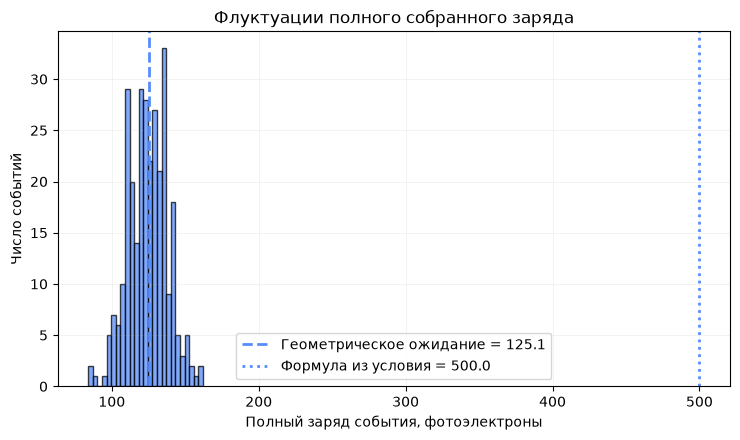

In [17]:
def simulate_total_charge_fast(
    detector: Detector,
    source: Source,
    energy_mev: float,
    a: float,
    rng: np.random.Generator,
) -> int:
    """Быстрый расчёт полного заряда серии событий без сохранения траекторий."""
    directions = source.generate_directions(energy_mev, rng=rng)
    # Для каждого фотона при источнике в центре точка попадания = R * direction.
    # Индекс ФЭУ определяется направлением, поскольку точка уже на сфере.
    cos_angles = directions @ detector.pmt_directions.T
    best = np.argmax(cos_angles, axis=1)
    covered = cos_angles[np.arange(len(directions)), best] >= np.cos(detector.theta_pmt)

    # Сумма независимых Poisson(a) по всем попавшим фотонам
    # эквивалентна Poisson(a * число попавших фотонов).
    n_hits = int(np.count_nonzero(covered))
    return int(rng.poisson(a * n_hits))


n_trials = 300
rng_trials = np.random.default_rng(314159)
charges = np.array([
    simulate_total_charge_fast(
        detector, source, EVENT_ENERGY_MEV, PHOTOELECTRON_MEAN, rng_trials
    )
    for _ in range(n_trials)
])

print(f"Число событий:                  {n_trials}")
print(f"Средний заряд по моделированию: {charges.mean():.2f} p.e.")
print(f"СКО между событиями:            {charges.std(ddof=1):.2f} p.e.")
print(f"Ожидание по точной геометрии:    {q_geometry:.2f} p.e.")
print(f"Ожидание по формуле задания:    {q_given:.2f} p.e.")

plt.figure(figsize=(7.5, 4.5))
plt.hist(charges, bins=25, edgecolor="black", alpha=0.75)
plt.axvline(q_geometry, linestyle="--", linewidth=2,
            label=f"Геометрическое ожидание = {q_geometry:.1f}")
plt.axvline(q_given, linestyle=":", linewidth=2,
            label=f"Формула из условия = {q_given:.1f}")
plt.xlabel("Полный заряд события, фотоэлектроны")
plt.ylabel("Число событий")
plt.title("Флуктуации полного собранного заряда")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 17. Выводы по задаче 3

Реализован полный алгоритм геометрического распространения фотонов и их регистрации:
- аналитически находится первое пересечение траектории со сферой;
- по точке пересечения определяется фотокатод, если он покрывает эту точку;
- для каждого попавшего фотона разыгрывается число фотоэлектронов $N_{pe}\sim\mathrm{Poisson}(a)$;
- суммирование по каналам даёт полный собранный заряд.

Метод генерации фотоэлектронов принадлежит `Photomultiplier`, так как описывает статистический отклик фотокатода. Метод `find_pmt_at_hit` относится к геометрии `Detector`, а генерация начальных направлений — к `Source`.

**Интерпретация сравнения с формулой из условия:** результат одного события не обязан совпадать с математическим ожиданием из-за флуктуаций числа фотонов, попаданий и фотоэлектронов. Для сравнения ожиданий следует использовать серию событий. Кроме того, при принятой геометрии фотокатодов естественное геометрическое покрытие сферы содержит множитель $1/4$; формула $Q=aY(Nr^2/R^2)$, приведённая в задании, в четыре раза больше приближения, следующего из площади фотокатодов на сферической поверхности. Это различие явно показано в расчётах.

# ЗАДАЧА 4. ЭНЕРГЕТИЧЕСКИЙ ОТКЛИК ДЕТЕКТОРА

**Что решается в этом разделе:** исследуется статистическое распределение полного собранного заряда при разных энергиях события и разных положениях источника.

Выполняются расчёты:
1. 1000 событий с энергией 1 МэВ при источнике в центре.
2. 1000 событий для каждой энергии: 0.2, 0.5, 0.7, 1.5, 2.0 и 3.0 МэВ.
3. Расчёт среднего заряда, стандартного отклонения и относительной ширины распределения.
4. 1000 событий с энергией 1 МэВ при смещении источника в точку `(0, 0, 1)` м.
5. Сравнение центрального и смещённого положения источника.

**Результат задачи:** распределения заряда, гистограммы, графики зависимости от энергии и сравнение отклика для двух положений источника.

# Задача 4. Энергетический отклик детектора

В этой части исследуем распределение полного собранного заряда при фиксированной энергии события и при изменении энергии. Также проверим влияние смещения источника на 1 м вдоль оси $z$.

План расчёта:
1. Смоделировать 1000 независимых событий с энергией 1 МэВ в центре детектора.
2. Повторить расчёт для энергий $0.2,\ 0.5,\ 0.7,\ 1.5,\ 2.0,\ 3.0$ МэВ.
3. Построить гистограммы полного заряда и вычислить среднее, стандартное отклонение и относительную ширину $\sigma_Q/\langle Q\rangle$.
4. Смоделировать 1000 событий с энергией 1 МэВ для источника в точке $(0,0,1)$ м.
5. Сравнить средние заряды для центрального и смещённого источников.

Для ускорения серии событий используется векторизованный расчёт геометрии. Статистическая модель остаётся той же, что в задаче 3: каждый фотон независимо попадает либо не попадает на фотокатод; при попадании число фотоэлектронов имеет распределение Пуассона с параметром $a$. Сумма независимых пуассоновских величин также распределена по Пуассону, поэтому полный заряд одного события можно разыграть как $\operatorname{Poisson}(aN_{hit})$.

## 18. Векторизованное моделирование серии событий

В отличие от полного пошагового моделирования одного события, здесь не требуется сохранять траекторию каждого фотона и распределение фотоэлектронов по каналам. Для каждого события достаточно определить количество фотонов, попавших на фотокатоды, а затем разыграть полный заряд.

Пересечение луча со сферой рассчитывается по той же формуле, что и в задаче 3. Расчёт выполняется небольшими пакетами событий, чтобы ограничить потребление оперативной памяти.

In [18]:
# ==================== ЗАДАЧА 4: СТАТИСТИКА ЭНЕРГЕТИЧЕСКОГО ОТКЛИКА ====================
def simulate_charge_ensemble(
    detector: Detector,
    source: Source,
    energy_mev: float,
    n_events: int = 1000,
    origin=(0.0, 0.0, 0.0),
    a: float = 0.5,
    seed: int = 12345,
    batch_events: int = 8,
) -> tuple[np.ndarray, np.ndarray]:
    """Смоделировать распределение полного заряда для серии событий.

    Возвращает
    ----------
    charges : ndarray, shape (n_events,)
        Полный заряд каждого события в фотоэлектронах.
    hit_counts : ndarray, shape (n_events,)
        Число фотонов, попавших на фотокатоды в каждом событии.
    """
    origin = np.asarray(origin, dtype=float)
    if origin.shape != (3,) or not np.all(np.isfinite(origin)):
        raise ValueError("origin должен быть конечным вектором длины 3.")
    if np.linalg.norm(origin) >= detector.R:
        raise ValueError("Источник должен находиться строго внутри детектора.")
    if not isinstance(n_events, (int, np.integer)) or n_events <= 0:
        raise ValueError("n_events должен быть положительным целым числом.")
    if batch_events <= 0:
        raise ValueError("batch_events должен быть положительным.")
    if not np.isfinite(a) or a < 0:
        raise ValueError("Параметр a должен быть конечным и неотрицательным.")

    rng = np.random.default_rng(seed)
    n_photons = source.photon_count(energy_mev)
    charges = np.empty(n_events, dtype=np.int64)
    hit_counts = np.empty(n_events, dtype=np.int64)

    pmt_threshold = np.cos(detector.theta_pmt)
    pmt_axes_transposed = detector.pmt_directions.T
    origin_norm2 = float(np.dot(origin, origin))

    for start in range(0, n_events, batch_events):
        stop = min(start + batch_events, n_events)
        current_batch = stop - start

        # Изотропные направления: phi ~ U(0, 2pi), cos(theta) ~ U(-1, 1).
        phi = rng.uniform(0.0, 2.0 * np.pi, size=(current_batch, n_photons))
        mu = rng.uniform(-1.0, 1.0, size=(current_batch, n_photons))
        transverse = np.sqrt(np.maximum(0.0, 1.0 - mu**2))

        directions = np.empty((current_batch, n_photons, 3), dtype=np.float32)
        directions[..., 0] = transverse * np.cos(phi)
        directions[..., 1] = transverse * np.sin(phi)
        directions[..., 2] = mu

        # Первое пересечение луча x(t) = origin + t*n со сферой.
        projection = np.einsum("bpi,i->bp", directions, origin)
        discriminant = projection**2 + detector.R**2 - origin_norm2
        distance = -projection + np.sqrt(np.maximum(discriminant, 0.0))

        hit_points = origin + distance[..., None] * directions
        hit_directions = hit_points / detector.R

        # Фотон зарегистрирован, если его направление на границе
        # находится внутри угловой шапочки хотя бы одного ФЭУ.
        cosine_to_pmts = hit_directions @ pmt_axes_transposed
        is_detected = np.max(cosine_to_pmts, axis=-1) >= pmt_threshold
        batch_hits = np.count_nonzero(is_detected, axis=1)

        hit_counts[start:stop] = batch_hits
        # Сумма N_hit независимых Poisson(a) величин имеет закон Poisson(a*N_hit).
        charges[start:stop] = rng.poisson(a * batch_hits)

    return charges, hit_counts


## 19. 1000 событий с энергией 1 МэВ в центре детектора

Сначала выполняем базовый расчёт, указанный в первом пункте задачи. Фиксируем seed для воспроизводимости серии.

In [19]:
N_EVENTS = 1000
BASE_ENERGY_MEV = 1.0
CENTER_ORIGIN = (0.0, 0.0, 0.0)

charges_1MeV, hits_1MeV = simulate_charge_ensemble(
    detector=detector,
    source=source,
    energy_mev=BASE_ENERGY_MEV,
    n_events=N_EVENTS,
    origin=CENTER_ORIGIN,
    a=PHOTOELECTRON_MEAN,
    seed=41001,
)

mean_1MeV = charges_1MeV.mean()
std_1MeV = charges_1MeV.std(ddof=1)
relative_width_1MeV = std_1MeV / mean_1MeV

print(f"Количество событий:          {N_EVENTS}")
print(f"Средний полный заряд:        {mean_1MeV:.3f} p.e.")
print(f"Стандартное отклонение:      {std_1MeV:.3f} p.e.")
print(f"Относительная ширина sigma/mean: {relative_width_1MeV:.4f}")
print(f"Среднее число фотонов на ФЭУ: {hits_1MeV.mean():.3f}")

Количество событий:          1000
Средний полный заряд:        124.791 p.e.
Стандартное отклонение:      13.614 p.e.
Относительная ширина sigma/mean: 0.1091
Среднее число фотонов на ФЭУ: 249.515


### Распределение полного собранного заряда при 1 МэВ

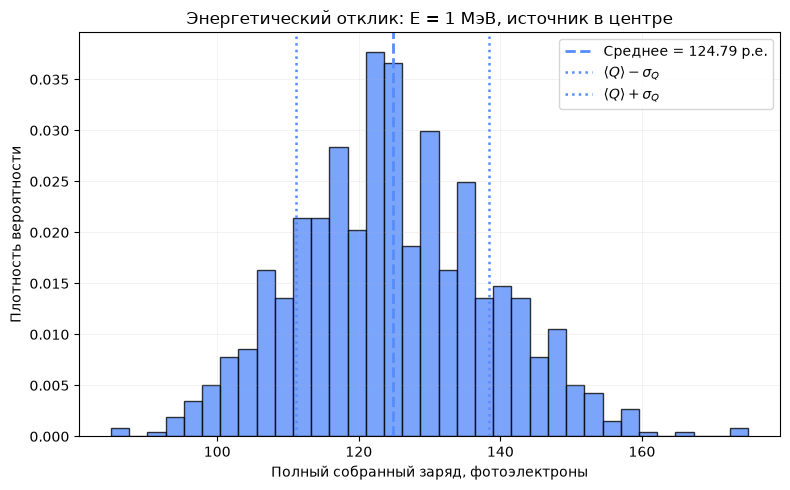

In [20]:
plt.figure(figsize=(8, 5))
plt.hist(charges_1MeV, bins=35, density=True, alpha=0.78, edgecolor="black")
plt.axvline(mean_1MeV, linestyle="--", linewidth=2,
            label=f"Среднее = {mean_1MeV:.2f} p.e.")
plt.axvline(mean_1MeV - std_1MeV, linestyle=":", linewidth=1.8,
            label=r"$\langle Q\rangle-\sigma_Q$")
plt.axvline(mean_1MeV + std_1MeV, linestyle=":", linewidth=1.8,
            label=r"$\langle Q\rangle+\sigma_Q$")
plt.xlabel("Полный собранный заряд, фотоэлектроны")
plt.ylabel("Плотность вероятности")
plt.title("Энергетический отклик: E = 1 МэВ, источник в центре")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 20. Зависимость распределения заряда от энергии

Повторяем моделирование для энергий из условия: $0.2,\ 0.5,\ 0.7,\ 1.5,\ 2.0,\ 3.0$ МэВ. Для сопоставимости используем по 1000 событий на каждую энергию. Центральная точка $(0,0,0)$ остаётся неизменной.

In [21]:
ENERGIES_MEV = [0.2, 0.5, 0.7, 1.5, 2.0, 3.0]
energy_results = {}

for index, energy_value in enumerate(ENERGIES_MEV):
    charges, hit_counts = simulate_charge_ensemble(
        detector=detector,
        source=source,
        energy_mev=energy_value,
        n_events=N_EVENTS,
        origin=CENTER_ORIGIN,
        a=PHOTOELECTRON_MEAN,
        seed=42000 + index,
    )
    energy_results[energy_value] = {
        "charges": charges,
        "hit_counts": hit_counts,
        "mean": float(charges.mean()),
        "std": float(charges.std(ddof=1)),
        "relative_width": float(charges.std(ddof=1) / charges.mean()),
    }

print("Энергия [МэВ] | Средний заряд [p.e.] | sigma [p.e.] | sigma/mean")
print("-" * 68)
for energy_value in ENERGIES_MEV:
    result = energy_results[energy_value]
    print(
        f"{energy_value:12.1f} | {result['mean']:19.3f} | "
        f"{result['std']:11.3f} | {result['relative_width']:10.4f}"
    )

Энергия [МэВ] | Средний заряд [p.e.] | sigma [p.e.] | sigma/mean
--------------------------------------------------------------------
         0.2 |              25.206 |       6.225 |     0.2470
         0.5 |              62.421 |       9.484 |     0.1519
         0.7 |              87.293 |      11.719 |     0.1343
         1.5 |             186.804 |      16.762 |     0.0897
         2.0 |             249.604 |      19.555 |     0.0783
         3.0 |             374.665 |      24.061 |     0.0642


### Гистограммы для всех энергий

Каждая панель соответствует 1000 независимым событиям. Общая нормировка по плотности позволяет сравнивать форму распределений, несмотря на различный масштаб заряда.

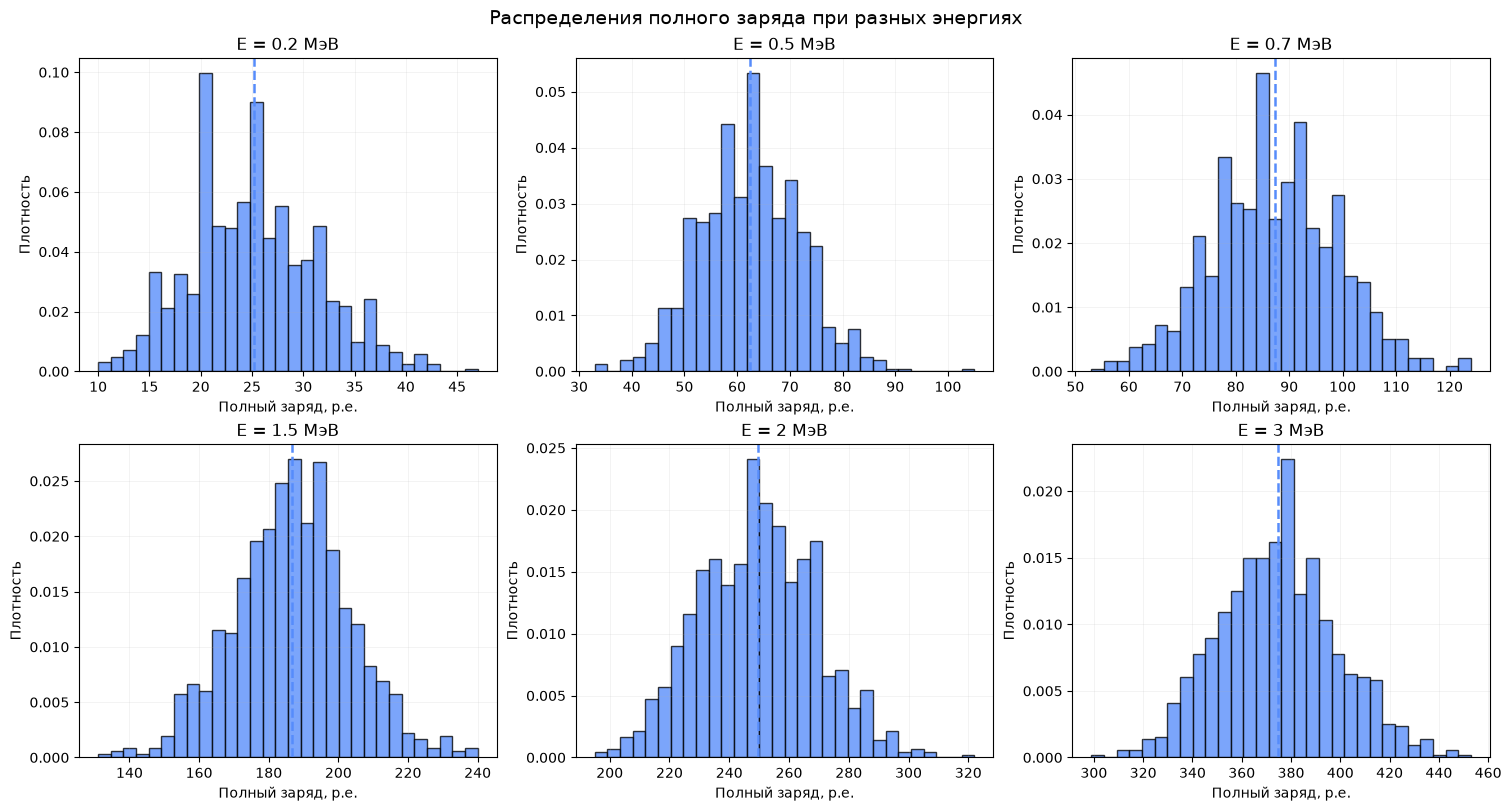

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, energy_value in zip(axes.flat, ENERGIES_MEV):
    result = energy_results[energy_value]
    ax.hist(result["charges"], bins=30, density=True,
            alpha=0.78, edgecolor="black")
    ax.axvline(result["mean"], linestyle="--", linewidth=1.8)
    ax.set_title(f"E = {energy_value:g} МэВ")
    ax.set_xlabel("Полный заряд, p.e.")
    ax.set_ylabel("Плотность")
    ax.grid(alpha=0.2)

fig.suptitle("Распределения полного заряда при разных энергиях", fontsize=14)
plt.show()

### Средний заряд и относительная ширина

Относительная ширина определяется как
$$
\frac{\sigma_Q}{\langle Q\rangle}.
$$
При увеличении энергии испускается больше фотонов и в среднем регистрируется больше фотоэлектронов. Поэтому относительные статистические флуктуации должны уменьшаться.

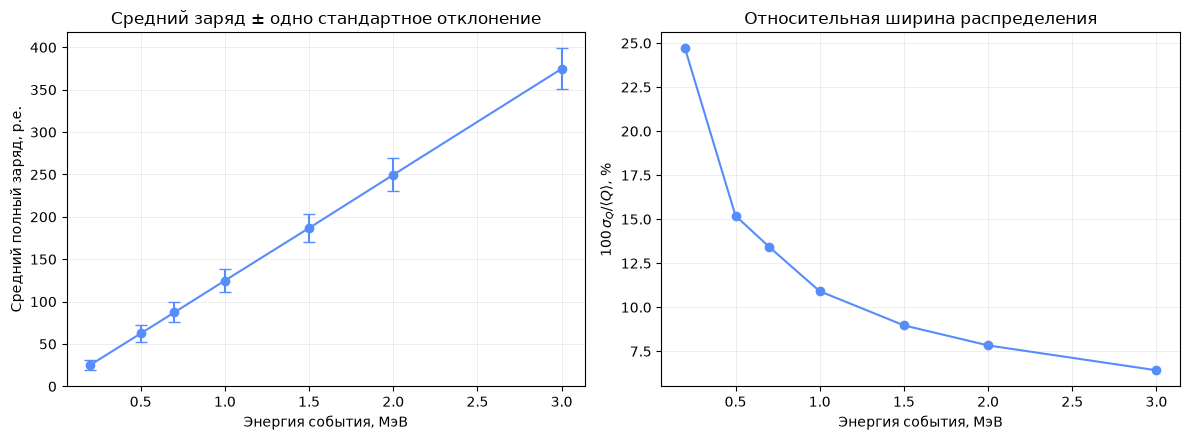

In [23]:
all_energies = [BASE_ENERGY_MEV] + ENERGIES_MEV
all_means = [mean_1MeV] + [energy_results[e]["mean"] for e in ENERGIES_MEV]
all_stds = [std_1MeV] + [energy_results[e]["std"] for e in ENERGIES_MEV]
all_rel_widths = [relative_width_1MeV] + [
    energy_results[e]["relative_width"] for e in ENERGIES_MEV
]

order = np.argsort(all_energies)
energies_sorted = np.asarray(all_energies)[order]
means_sorted = np.asarray(all_means)[order]
stds_sorted = np.asarray(all_stds)[order]
rel_sorted = np.asarray(all_rel_widths)[order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].errorbar(energies_sorted, means_sorted, yerr=stds_sorted,
                 fmt="o-", capsize=4)
axes[0].set(
    xlabel="Энергия события, МэВ",
    ylabel="Средний полный заряд, p.e.",
    title="Средний заряд ± одно стандартное отклонение",
)
axes[0].grid(alpha=0.3)

axes[1].plot(energies_sorted, 100 * rel_sorted, "o-")
axes[1].set(
    xlabel="Энергия события, МэВ",
    ylabel=r"$100\,\sigma_Q/\langle Q\rangle$, %",
    title="Относительная ширина распределения",
)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 21. Смещение источника на 1 м вдоль оси z

Теперь сравним центральный источник с источником в точке
$$
\mathbf{x}_0=(0,0,1)\ \text{м}.
$$
Радиус детектора равен 2 м, поэтому смещённый источник остаётся внутри активного объёма.

При смещении источника изотропное излучение сохраняется, но фотоумножители видны из точки рождения под разными телесными углами. Поэтому вероятность попадания фотона на фотокатод и средний собранный заряд могут измениться. Выполним по 1000 событий для обеих конфигураций.

In [24]:
OFFSET_ORIGIN = (0.0, 0.0, 1.0)

charges_offset, hits_offset = simulate_charge_ensemble(
    detector=detector,
    source=source,
    energy_mev=BASE_ENERGY_MEV,
    n_events=N_EVENTS,
    origin=OFFSET_ORIGIN,
    a=PHOTOELECTRON_MEAN,
    seed=43001,
)

mean_offset = charges_offset.mean()
std_offset = charges_offset.std(ddof=1)
relative_offset = std_offset / mean_offset

mean_change = mean_offset - mean_1MeV
percent_change = 100.0 * mean_change / mean_1MeV

print(f"Центральный источник: mean = {mean_1MeV:.3f} p.e., sigma = {std_1MeV:.3f} p.e.")
print(f"Смещённый источник:   mean = {mean_offset:.3f} p.e., sigma = {std_offset:.3f} p.e.")
print(f"Изменение среднего:   {mean_change:+.3f} p.e. ({percent_change:+.2f}%)")
print(f"Относительная ширина, центр:   {relative_width_1MeV:.4f}")
print(f"Относительная ширина, смещение: {relative_offset:.4f}")

Центральный источник: mean = 124.791 p.e., sigma = 13.614 p.e.
Смещённый источник:   mean = 125.545 p.e., sigma = 13.277 p.e.
Изменение среднего:   +0.754 p.e. (+0.60%)
Относительная ширина, центр:   0.1091
Относительная ширина, смещение: 0.1058


### Сравнение распределений для центрального и смещённого источников

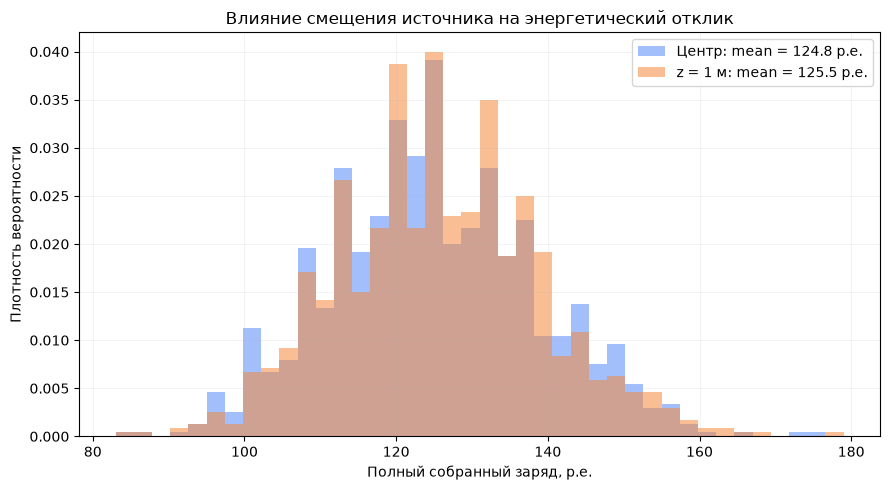

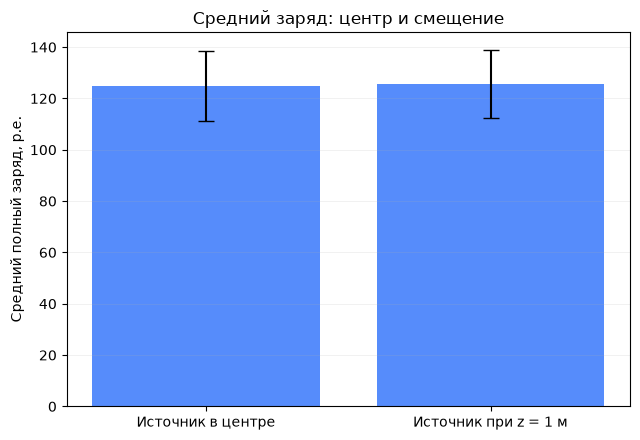

In [25]:
plt.figure(figsize=(9, 5))
bins = np.histogram_bin_edges(
    np.concatenate([charges_1MeV, charges_offset]), bins=40
)
plt.hist(charges_1MeV, bins=bins, density=True, alpha=0.55,
         label=f"Центр: mean = {mean_1MeV:.1f} p.e.")
plt.hist(charges_offset, bins=bins, density=True, alpha=0.55,
         label=f"z = 1 м: mean = {mean_offset:.1f} p.e.")
plt.xlabel("Полный собранный заряд, p.e.")
plt.ylabel("Плотность вероятности")
plt.title("Влияние смещения источника на энергетический отклик")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6.5, 4.5))
plt.bar(
    ["Источник в центре", "Источник при z = 1 м"],
    [mean_1MeV, mean_offset],
    yerr=[std_1MeV, std_offset],
    capsize=6,
)
plt.ylabel("Средний полный заряд, p.e.")
plt.title("Средний заряд: центр и смещение")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 22. K3D: визуализация детектора со смещённым источником

Покажем работу детектора для смещённого источника. Используется одно полноценное событие с энергией 1 МэВ и координатами $(0,0,1)$ м. Как и ранее, в 3D отображается выборка фотонных траекторий; все статистические результаты выше получены по полным сериям из 1000 событий.

In [26]:
offset_event = simulate_event(
    detector=detector,
    source=source,
    energy_mev=BASE_ENERGY_MEV,
    origin=OFFSET_ORIGIN,
    a=PHOTOELECTRON_MEAN,
    seed=43002,
)

print(f"Источник: {offset_event['origin']} м")
print(f"Испущено фотонов: {offset_event['n_photons']:,}")
print(f"Попало на фотокатоды: {offset_event['detected_photons']:,}")
print(f"Полный заряд этого события: {offset_event['total_photoelectrons']:,} p.e.")

offset_event_plot = visualize_event_k3d(
    detector,
    offset_event,
    max_tracks=500,
)
offset_event_plot

Источник: [0. 0. 1.] м
Испущено фотонов: 10,000
Попало на фотокатоды: 274
Полный заряд этого события: 130 p.e.


## 23. Итоги задачи 4

Выполнено моделирование по 1000 событий:
- для энергии 1 МэВ в центре детектора;
- для энергий 0.2, 0.5, 0.7, 1.5, 2.0 и 3.0 МэВ в центре;
- для энергии 1 МэВ при смещении источника на 1 м вдоль оси $z$.

Для каждого набора получены распределения полного собранного заряда, среднее значение, стандартное отклонение и относительная ширина $\sigma_Q/\langle Q\rangle$.

**Физическая интерпретация.** В линейной модели световыхода средний заряд растёт приблизительно пропорционально энергии. При этом абсолютная ширина распределения растёт примерно как квадратный корень из среднего числа зарегистрированных фотоэлектронов, а относительная ширина уменьшается с энергией. Смещение источника меняет видимые телесные углы фотокатодов и, следовательно, геометрическую эффективность сбора света. Численное изменение среднего заряда определяется результатами моделирования, выведенными выше.

Для надёжного сравнения используйте средние по 1000 событий, а не заряд одного случайного события. K3D-сцены показывают геометрию, траектории и попадания для центрального и смещённого источников.

# ЗАДАЧА 5. БОЛЕЕ УМНЫЙ ИСТОЧНИК

**Что решается в этом разделе:** источник расширяется так, чтобы число фотонов при фиксированной энергии было случайным и подчинялось распределению Пуассона. Генерация направлений реализуется как Python-генератор: за один вызов `yield` он возвращает пакет из 100 фотонов.

Выполняются все пункты задания:
1. Для энергии $E$ разыгрывается число фотонов $N_\gamma\sim\operatorname{Poisson}(EY)$.
2. Генерация направлений из задачи 2 оформляется как генератор Python.
3. Генератор выдаёт по 100 фотонов (последний пакет может быть короче 100, если общее число не кратно 100).
4. Проверяется статистика числа фотонов и моделируется прохождение такого события через детектор.
5. Работа детектора для события из задачи 5 показывается в интерактивной 3D-сцене **K3D**.

**Совместимость с задачами 1–4:** прежний класс `Source` и детерминированный метод `generate_directions` не изменяются. Новый класс `SmartSource` наследует `Source` и добавляет пуассоновскую модель, поэтому результаты предыдущих разделов сохраняются.

## 24. Физическая модель более умного источника

Для заданной энергии $E$ среднее число фотонов равно
$$
\lambda=EY,
$$
а фактическое число фотонов случайно:
$$
N_\gamma\sim\operatorname{Poisson}(\lambda),\qquad
P(N_\gamma=n)=\frac{\lambda^n e^{-\lambda}}{n!}.
$$
Для распределения Пуассона
$$
\mathbb E[N_\gamma]=\lambda=EY,\qquad
\operatorname{Var}(N_\gamma)=\lambda,\qquad
\sigma_{N_\gamma}=\sqrt{EY}.
$$

При $Y=10\,000$ фотонов/МэВ и $E=1$ МэВ получаем $\lambda=10\,000$ и $\sigma_{N_\gamma}=100$. Поэтому число фотонов в разных событиях будет немного отличаться, хотя энергия фиксирована.

## 25. Реализация `SmartSource` и генератора пакетов

Метод `photon_count_poisson` один раз разыгрывает общее число фотонов события. Метод `generate_photons` является генератором: он последовательно создаёт изотропные направления и возвращает массив формы `(100, 3)` при каждом `yield`. Это ограничивает объём данных, одновременно находящихся в памяти, и позволяет обрабатывать фотонные пакеты по очереди.

In [27]:
# ==================== ЗАДАЧА 5: ПУАССОНОВСКИЙ ИСТОЧНИК ====================
class SmartSource(Source):
    """Расширенный источник с пуассоновским числом фотонов.

    Унаследованный Source сохраняет детерминированный режим задач 1–4.
    В SmartSource число фотонов в каждом событии разыгрывается из Poisson(E*Y).
    """

    def photon_count_poisson(
        self,
        E: float,
        rng: Optional[np.random.Generator] = None,
    ) -> int:
        """Случайное число фотонов N ~ Poisson(Y * E)."""
        if not np.isfinite(E) or E < 0:
            raise ValueError("Энергия E должна быть конечной и неотрицательной.")
        rng = np.random.default_rng() if rng is None else rng
        mean_photons = self.Y * float(E)
        return int(rng.poisson(mean_photons))

    def generate_photons(
        self,
        E: float,
        rng: Optional[np.random.Generator] = None,
        batch_size: int = 100,
    ):
        """Генератор пакетов изотропных направлений фотонов.

        Каждый yield возвращает ndarray формы (batch_size, 3).
        Последний пакет содержит оставшиеся фотоны и может быть короче.
        Общее число фотонов разыгрывается из Poisson(Y * E) один раз.
        """
        if not isinstance(batch_size, (int, np.integer)) or isinstance(batch_size, bool) or batch_size <= 0:
            raise ValueError("batch_size должен быть положительным целым числом.")

        rng = np.random.default_rng() if rng is None else rng
        n_photons = self.photon_count_poisson(E, rng=rng)

        for start in range(0, n_photons, int(batch_size)):
            current_size = min(int(batch_size), n_photons - start)
            phi = rng.uniform(0.0, 2.0 * np.pi, size=current_size)
            cos_theta = rng.uniform(-1.0, 1.0, size=current_size)
            sin_theta = np.sqrt(np.maximum(0.0, 1.0 - cos_theta**2))

            directions = np.column_stack((
                sin_theta * np.cos(phi),
                sin_theta * np.sin(phi),
                cos_theta,
            ))
            yield directions


smart_source = SmartSource(Y=source.Y)
print(f"Световыход SmartSource: {smart_source.Y:,.0f} фотонов/МэВ")
print("Математическое ожидание числа фотонов при 1 МэВ:",
      f"{smart_source.Y * 1.0:,.0f}")

Световыход SmartSource: 10,000 фотонов/МэВ
Математическое ожидание числа фотонов при 1 МэВ: 10,000


## 26. Проверка `yield`: выдача фотонов блоками по 100

Вызов `generate_photons` возвращает итератор, а не готовый массив всех фотонов. При обходе итератора каждый `yield` передаёт следующий пакет. Проверим размеры пакетов и единичную длину направлений.

In [28]:
GENERATOR_ENERGY_MEV = 1.0
BATCH_SIZE = 100
rng_generator_demo = np.random.default_rng(50501)

photon_batches = list(smart_source.generate_photons(
    GENERATOR_ENERGY_MEV,
    rng=rng_generator_demo,
    batch_size=BATCH_SIZE,
))

batch_sizes = np.array([len(batch) for batch in photon_batches], dtype=int)
if photon_batches:
    generator_directions = np.concatenate(photon_batches, axis=0)
else:
    generator_directions = np.empty((0, 3), dtype=float)

n_generated = len(generator_directions)
print(f"Энергия события:              {GENERATOR_ENERGY_MEV:.2f} МэВ")
print(f"Число выданных пакетов:       {len(photon_batches)}")
print(f"Всего сгенерировано фотонов:  {n_generated:,}")
print(f"Размеры первых пакетов:       {batch_sizes[:5]}")
print(f"Размер последнего пакета:     {batch_sizes[-1] if len(batch_sizes) else 0}")

assert all(size == BATCH_SIZE for size in batch_sizes[:-1])
assert len(batch_sizes) == 0 or 1 <= batch_sizes[-1] <= BATCH_SIZE
if n_generated:
    assert np.allclose(np.linalg.norm(generator_directions, axis=1), 1.0, atol=1e-12)

print("Проверка генератора пройдена: каждый yield выдаёт до 100 единичных направлений.")

Энергия события:              1.00 МэВ
Число выданных пакетов:       100
Всего сгенерировано фотонов:  9,962
Размеры первых пакетов:       [100 100 100 100 100]
Размер последнего пакета:     62
Проверка генератора пройдена: каждый yield выдаёт до 100 единичных направлений.


## 27. Статистическая проверка распределения Пуассона

Разыграем число фотонов для большого числа независимых событий с одной и той же энергией. Сравним выборочные среднее и дисперсию с теоретическим значением $EY$. На графике эмпирическое распределение сравнивается с точной вероятностью Пуассона, сгруппированной по небольшим интервалам.

Число независимых событий:       5,000
Теоретическое среднее EY:        10,000.00
Выборочное среднее:              9,999.54
Теоретическая дисперсия EY:      10,000.00
Выборочная дисперсия:            10,141.12
Теоретическое СКО sqrt(EY):      100.00
Выборочное СКО:                  100.70


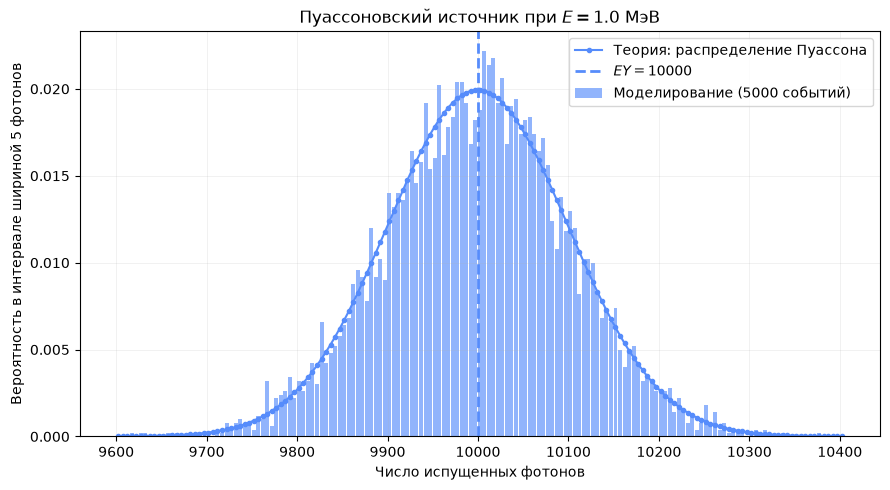

In [29]:
from math import lgamma

N_SOURCE_TRIALS = 5_000
POISSON_ENERGY_MEV = 1.0
LAMBDA_PHOTONS = smart_source.Y * POISSON_ENERGY_MEV
rng_poisson_stats = np.random.default_rng(50502)

photon_count_samples = np.array([
    smart_source.photon_count_poisson(POISSON_ENERGY_MEV, rng=rng_poisson_stats)
    for _ in range(N_SOURCE_TRIALS)
], dtype=np.int64)

sample_mean_photons = float(photon_count_samples.mean())
sample_variance_photons = float(photon_count_samples.var(ddof=1))
sample_std_photons = float(photon_count_samples.std(ddof=1))
theory_std_photons = np.sqrt(LAMBDA_PHOTONS)

print(f"Число независимых событий:       {N_SOURCE_TRIALS:,}")
print(f"Теоретическое среднее EY:        {LAMBDA_PHOTONS:,.2f}")
print(f"Выборочное среднее:              {sample_mean_photons:,.2f}")
print(f"Теоретическая дисперсия EY:      {LAMBDA_PHOTONS:,.2f}")
print(f"Выборочная дисперсия:            {sample_variance_photons:,.2f}")
print(f"Теоретическое СКО sqrt(EY):      {theory_std_photons:,.2f}")
print(f"Выборочное СКО:                  {sample_std_photons:,.2f}")

# Точная функция вероятности Пуассона вычисляется через log(n!),
# чтобы избежать переполнения при больших n.
low = int(np.floor(LAMBDA_PHOTONS - 4.0 * theory_std_photons))
high = int(np.ceil(LAMBDA_PHOTONS + 4.0 * theory_std_photons))
k_values = np.arange(low, high + 1)
log_pmf = np.array([
    k * np.log(LAMBDA_PHOTONS) - LAMBDA_PHOTONS - lgamma(k + 1)
    for k in k_values
])
poisson_pmf = np.exp(log_pmf)

bin_edges = np.arange(low - 0.5, high + 5.5, 5.0)
empirical_frequency, _ = np.histogram(photon_count_samples, bins=bin_edges)
empirical_probability = empirical_frequency / N_SOURCE_TRIALS
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
theory_probability = np.array([
    poisson_pmf[(k_values >= left) & (k_values < right)].sum()
    for left, right in zip(bin_edges[:-1], bin_edges[1:])
])

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(bin_centers, empirical_probability, width=4.4, alpha=0.65,
       label="Моделирование (5000 событий)")
ax.plot(bin_centers, theory_probability, "o-", markersize=3,
        linewidth=1.5, label="Теория: распределение Пуассона")
ax.axvline(LAMBDA_PHOTONS, linestyle="--", linewidth=2,
           label=rf"$EY={LAMBDA_PHOTONS:.0f}$")
ax.set(
    xlabel="Число испущенных фотонов",
    ylabel="Вероятность в интервале шириной 5 фотонов",
    title=rf"Пуассоновский источник при $E={POISSON_ENERGY_MEV:.1f}$ МэВ",
)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 28. Прохождение пуассоновского события через детектор

Теперь используем генератор непосредственно в моделировании детектора. Фотонные направления обрабатываются пакетами по 100: для каждого пакета вычисляются пересечения со сферой и попадания на фотокатоды. Фотоэлектроны разыгрываются независимо по закону $N_{pe}\sim\operatorname{Poisson}(a)$ для каждого попавшего фотона.

Результат имеет ту же структуру, что и `simulate_event` из задачи 3, поэтому существующая функция `visualize_event_k3d` может без изменений визуализировать и новое пуассоновское событие.

In [30]:
# ==================== ЗАДАЧА 5: МОДЕЛИРОВАНИЕ СОБЫТИЯ ПАКЕТАМИ ====================
def simulate_smart_event(
    detector: Detector,
    source: SmartSource,
    energy_mev: float,
    origin=(0.0, 0.0, 0.0),
    a: float = 0.5,
    seed: int = 50503,
    batch_size: int = 100,
) -> dict:
    """Полная симуляция события с Poisson(E*Y) и пакетной генерацией фотонов."""
    origin = np.asarray(origin, dtype=float)
    if origin.shape != (3,) or not np.all(np.isfinite(origin)):
        raise ValueError("origin должен быть конечным вектором длины 3.")
    if np.linalg.norm(origin) >= detector.R:
        raise ValueError("Источник должен находиться строго внутри детектора.")
    if not np.isfinite(a) or a < 0:
        raise ValueError("Параметр a должен быть конечным и неотрицательным.")

    rng = np.random.default_rng(seed)
    direction_chunks = []
    hit_chunks = []
    distance_chunks = []
    pmt_index_chunks = []
    photoelectron_chunks = []
    pmt_counts = np.zeros(detector.N, dtype=np.int64)

    pmt_threshold = np.cos(detector.theta_pmt)
    pmt_axes_transposed = detector.pmt_directions.T
    origin_norm2 = float(np.dot(origin, origin))

    for directions in source.generate_photons(
        energy_mev, rng=rng, batch_size=batch_size
    ):
        # Аналитическое первое пересечение луча со сферой — сразу для всего пакета.
        projection = directions @ origin
        discriminant = projection**2 + detector.R**2 - origin_norm2
        distances = -projection + np.sqrt(np.maximum(discriminant, 0.0))
        hit_points = origin + distances[:, None] * directions
        hit_directions = hit_points / detector.R

        cosine_to_pmts = hit_directions @ pmt_axes_transposed
        best_pmt = np.argmax(cosine_to_pmts, axis=1)
        detected = np.max(cosine_to_pmts, axis=1) >= pmt_threshold
        pmt_indices = np.where(detected, best_pmt, -1)

        photoelectrons = np.zeros(len(directions), dtype=np.int64)
        n_detected = int(np.count_nonzero(detected))
        if n_detected:
            photoelectrons[detected] = rng.poisson(a, size=n_detected)
            np.add.at(pmt_counts, best_pmt[detected], photoelectrons[detected])

        direction_chunks.append(directions)
        hit_chunks.append(hit_points)
        distance_chunks.append(distances)
        pmt_index_chunks.append(pmt_indices)
        photoelectron_chunks.append(photoelectrons)

    def concatenate_or_empty(chunks, shape, dtype=float):
        return np.concatenate(chunks, axis=0) if chunks else np.empty(shape, dtype=dtype)

    directions = concatenate_or_empty(direction_chunks, (0, 3))
    hit_points = concatenate_or_empty(hit_chunks, (0, 3))
    path_lengths = concatenate_or_empty(distance_chunks, (0,), dtype=float)
    pmt_indices = concatenate_or_empty(pmt_index_chunks, (0,), dtype=int)
    photoelectrons = concatenate_or_empty(photoelectron_chunks, (0,), dtype=int)

    return {
        "origin": origin,
        "directions": directions,
        "hit_points": hit_points,
        "path_lengths": path_lengths,
        "pmt_indices": pmt_indices,
        "photoelectrons": photoelectrons,
        "pmt_counts": pmt_counts,
        "total_photoelectrons": int(photoelectrons.sum()),
        "detected_photons": int(np.count_nonzero(pmt_indices >= 0)),
        "n_photons": int(len(directions)),
    }


SMART_EVENT_ENERGY_MEV = 1.0
SMART_EVENT_ORIGIN = (0.0, 0.0, 0.0)
SMART_EVENT = simulate_smart_event(
    detector=detector,
    source=smart_source,
    energy_mev=SMART_EVENT_ENERGY_MEV,
    origin=SMART_EVENT_ORIGIN,
    a=PHOTOELECTRON_MEAN,
    seed=50503,
    batch_size=100,
)

print(f"Энергия события:                 {SMART_EVENT_ENERGY_MEV:.2f} МэВ")
print(f"Теоретическое среднее EY:       {smart_source.Y * SMART_EVENT_ENERGY_MEV:,.0f} фотонов")
print(f"Фактически испущено:            {SMART_EVENT['n_photons']:,} фотонов")
print(f"Размер пакета генерации:        100 фотонов")
print(f"Попало на фотокатоды:           {SMART_EVENT['detected_photons']:,}")
print(f"Геометрическая эффективность:   {SMART_EVENT['detected_photons'] / max(SMART_EVENT['n_photons'], 1):.4%}")
print(f"Полное число фотоэлектронов:     {SMART_EVENT['total_photoelectrons']:,} p.e.")

assert SMART_EVENT["n_photons"] == len(SMART_EVENT["directions"])
assert SMART_EVENT["hit_points"].shape == (SMART_EVENT["n_photons"], 3)
assert SMART_EVENT["pmt_counts"].sum() == SMART_EVENT["total_photoelectrons"]

Энергия события:                 1.00 МэВ
Теоретическое среднее EY:       10,000 фотонов
Фактически испущено:            10,020 фотонов
Размер пакета генерации:        100 фотонов
Попало на фотокатоды:           258
Геометрическая эффективность:   2.5749%
Полное число фотоэлектронов:     136 p.e.


### Распределение фотоэлектронов по ФЭУ для пуассоновского события

График показывает, какие каналы зарегистрировали фотоэлектроны в выбранной реализации случайного события.

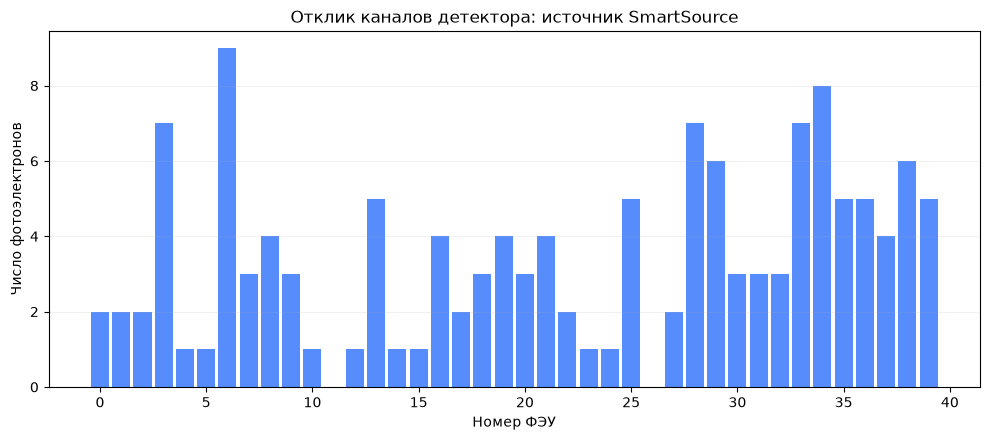

In [31]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(np.arange(detector.N), SMART_EVENT["pmt_counts"], width=0.85)
ax.set(
    xlabel="Номер ФЭУ",
    ylabel="Число фотоэлектронов",
    title="Отклик каналов детектора: источник SmartSource",
)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 29. 3D-визуализация работы детектора в K3D

На интерактивной сцене показаны сферическая граница детектора, фотоумножители, точка рождения события и выбранные траектории фотонов из пуассоновского источника. Зелёным цветом обозначены фотоны, попавшие на фотокатоды, красным — фотоны, прошедшие мимо них. Используется та же проверенная функция `visualize_event_k3d`, что и в задаче 3.

In [32]:
# K3D обязателен: здесь визуализируется именно событие из задачи 5.
smart_event_plot = visualize_event_k3d(
    detector,
    SMART_EVENT,
    max_tracks=600,
)
smart_event_plot

## 30. Итоги задачи 5

- Число фотонов для заданной энергии теперь случайно и распределено по Пуассону с параметром $\lambda=EY$.
- Проверено равенство теоретических среднего и дисперсии: $\mathbb E[N_\gamma]=\operatorname{Var}(N_\gamma)=EY$.
- Генерация направлений оформлена как Python-генератор: каждый `yield` возвращает пакет из 100 единичных изотропных направлений (последний пакет — остаток).
- Пакетный генератор включён в полный цикл моделирования: пересечение сферы, определение ФЭУ, генерация фотоэлектронов и подсчёт заряда.
- Работа детектора для случайного пуассоновского события показана в интерактивной сцене K3D.

**Итог:** задача 5 реализована отдельно через `SmartSource`, а готовые решения задач 1–4 и их визуализации сохранены без изменения физической модели.

# ЗАДАЧА 6. ЗАТУХАНИЕ СВЕТА В СЦИНТИЛЛЯТОРЕ

**Цель:** учесть экспоненциальное затухание сцинтилляционного света и определить, как оно меняет энергетический отклик детектора для источника с энергией 1 МэВ, расположенного в разных точках вертикальной оси.

Параметры и допущения:
- радиус сферического детектора: $R=2$ м;
- световыход источника: $Y=10\,000$ фотонов/МэВ, поэтому при $E=1$ МэВ испускается $10\,000$ фотонов;
- средний отклик фотокатода: $a=0.5$ фотоэлектрона на один попавший фотон;
- длина затухания: $L_{\mathrm{att}}=8$ м;
- точки источника: $(0,0,z)$ при нескольких значениях $z$ внутри сферы.

Для каждого положения источника будут рассчитаны два распределения полного собранного заряда:
1. без затухания — как в задаче 4;
2. с затуханием — с учётом вероятности выживания каждого фотона на пути до поверхности.

В каждой паре сравнений используются одинаковые наборы исходных направлений фотонов. Поэтому различие между двумя откликами обусловлено именно затуханием, а не случайным различием направлений.

## 31. Физическая модель экспоненциального затухания

При прохождении расстояния $s$ интенсивность света уменьшается по закону Бугера — Ламберта:

$$
I(s)=I_0\exp\left(-\frac{s}{L_{\mathrm{att}}}\right),
\qquad L_{\mathrm{att}}=8\text{ м}.
$$

В фотонной модели это означает, что каждый испущенный фотон независимо сохраняется с вероятностью

$$
P_{\mathrm{surv}}(s)=\exp\left(-\frac{s}{8\text{ м}}\right).
$$

Здесь $s$ — расстояние от точки рождения фотона до внутренней поверхности сферы, вычисляемое из геометрии луча. Если фотон не поглощён в жидкости, далее проверяется попадание на фотокатод. Для попавшего на фотокатод фотона число фотоэлектронов по-прежнему задаётся распределением $N_{pe}\sim\operatorname{Poisson}(a)$.

Таким образом, в отличие от задачи 4, фотон может не дойти до поверхности из-за поглощения. Геометрия детектора, расположение ФЭУ и их фотоэлектронный отклик не меняются.

## 32. Реализация моделирования с затуханием

Функция ниже рассчитывает серии событий пакетами, чтобы не хранить все траектории одновременно. Для каждого пакета она:

1. генерирует изотропные направления;
2. вычисляет длину пути до сферической поверхности;
3. определяет попадания на фотокатоды без затухания;
4. разыгрывает выживание фотонов с вероятностью $\exp(-s/L_{\mathrm{att}})$;
5. повторно подсчитывает попадания с учётом поглощения;
6. генерирует полный заряд как $Q\sim\operatorname{Poisson}(aN_{hit})$.

Сумма независимых пуассоновских откликов фотокатодов также имеет распределение Пуассона, поэтому для полного заряда достаточно одного розыгрыша с параметром $aN_{hit}$.

In [33]:
# ==================== ЗАДАЧА 6: МОДЕЛИРОВАНИЕ ЗАТУХАНИЯ ====================
def simulate_charge_ensemble_with_attenuation(
    detector: Detector,
    source: Source,
    energy_mev: float,
    attenuation_length: float = 8.0,
    n_events: int = 1000,
    origin=(0.0, 0.0, 0.0),
    a: float = 0.5,
    seed: int = 62001,
    batch_events: int = 8,
) -> dict:
    """Смоделировать отклик с затуханием и без него для одних фотонных лучей.

    Для каждого события генерируется один набор направлений. Он используется
    и для базового расчёта без затухания, и для расчёта с поглощением.
    Возвращаются массивы полного заряда и числа геометрических попаданий.
    """
    origin = np.asarray(origin, dtype=float)
    if origin.shape != (3,) or not np.all(np.isfinite(origin)):
        raise ValueError("origin должен быть конечным вектором длины 3.")
    if np.linalg.norm(origin) >= detector.R:
        raise ValueError("Источник должен находиться строго внутри детектора.")
    if not np.isfinite(attenuation_length) or attenuation_length <= 0:
        raise ValueError("Длина затухания должна быть конечной и положительной.")
    if not isinstance(n_events, (int, np.integer)) or n_events <= 0:
        raise ValueError("n_events должен быть положительным целым числом.")
    if not isinstance(batch_events, (int, np.integer)) or batch_events <= 0:
        raise ValueError("batch_events должен быть положительным целым числом.")
    if not np.isfinite(a) or a < 0:
        raise ValueError("Параметр a должен быть конечным и неотрицательным.")

    rng = np.random.default_rng(seed)
    n_photons = source.photon_count(energy_mev)

    charges_no_attenuation = np.empty(n_events, dtype=np.int64)
    charges_with_attenuation = np.empty(n_events, dtype=np.int64)
    hits_no_attenuation = np.empty(n_events, dtype=np.int64)
    hits_with_attenuation = np.empty(n_events, dtype=np.int64)

    pmt_threshold = np.cos(detector.theta_pmt)
    pmt_axes_transposed = detector.pmt_directions.T
    origin_norm2 = float(np.dot(origin, origin))

    total_path_length = 0.0
    total_survival_probability = 0.0
    survival_probability_on_pmt_rays_sum = 0.0
    number_of_pmt_rays = 0

    for start in range(0, n_events, batch_events):
        stop = min(start + batch_events, n_events)
        current_batch = stop - start

        # Изотропные направления: phi равномерна на [0, 2*pi),
        # а mu = cos(theta) равномерна на [-1, 1].
        phi = rng.uniform(0.0, 2.0 * np.pi, size=(current_batch, n_photons))
        mu = rng.uniform(-1.0, 1.0, size=(current_batch, n_photons))
        transverse = np.sqrt(np.maximum(0.0, 1.0 - mu**2))

        directions = np.empty((current_batch, n_photons, 3), dtype=np.float32)
        directions[..., 0] = transverse * np.cos(phi)
        directions[..., 1] = transverse * np.sin(phi)
        directions[..., 2] = mu

        # Расстояние до первого пересечения луча со сферой |x| = R.
        projection = np.einsum("bpi,i->bp", directions, origin)
        discriminant = projection**2 + detector.R**2 - origin_norm2
        distance = -projection + np.sqrt(np.maximum(discriminant, 0.0))

        # Направление точки попадания на сферической поверхности.
        hit_points = origin + distance[..., None] * directions
        hit_directions = hit_points / detector.R

        # Геометрическое попадание хотя бы на один фотокатод (без затухания).
        cosine_to_pmts = hit_directions @ pmt_axes_transposed
        geometrical_hits = (
            np.max(cosine_to_pmts, axis=-1) >= pmt_threshold
        )

        # Независимое поглощение каждого фотона на пути до поверхности.
        survival_probability = np.exp(-distance / attenuation_length)
        survived = rng.random(size=distance.shape) < survival_probability
        hits_after_attenuation = geometrical_hits & survived

        batch_hits_no = np.count_nonzero(geometrical_hits, axis=1)
        batch_hits_att = np.count_nonzero(hits_after_attenuation, axis=1)

        hits_no_attenuation[start:stop] = batch_hits_no
        hits_with_attenuation[start:stop] = batch_hits_att

        # Сумма N_hit независимых Poisson(a) величин имеет закон Poisson(a*N_hit).
        charges_no_attenuation[start:stop] = rng.poisson(a * batch_hits_no)
        charges_with_attenuation[start:stop] = rng.poisson(a * batch_hits_att)

        total_path_length += float(distance.sum())
        total_survival_probability += float(survival_probability.sum())
        if np.any(geometrical_hits):
            survival_probability_on_pmt_rays_sum += float(
                survival_probability[geometrical_hits].sum()
            )
            number_of_pmt_rays += int(np.count_nonzero(geometrical_hits))

    total_photons = n_events * n_photons
    return {
        "charges_no_attenuation": charges_no_attenuation,
        "charges_with_attenuation": charges_with_attenuation,
        "hits_no_attenuation": hits_no_attenuation,
        "hits_with_attenuation": hits_with_attenuation,
        "n_photons_per_event": n_photons,
        "mean_path_length": total_path_length / total_photons,
        "mean_survival_probability": total_survival_probability / total_photons,
        "mean_survival_probability_on_pmt_rays": (
            survival_probability_on_pmt_rays_sum / number_of_pmt_rays
            if number_of_pmt_rays else np.nan
        ),
    }

print("Функция моделирования с экспоненциальным затуханием определена.")

Функция моделирования с экспоненциальным затуханием определена.


## 33. Энергетический отклик для разных координат источника

Рассмотрим пять положений источника вдоль вертикальной оси:

$$
\mathbf{x}_0=(0,0,z),\qquad z\in\{-1.5,-1.0,0,1.0,1.5\}\text{ м}.
$$

Все точки находятся внутри сферического детектора радиуса 2 м. Для каждого положения моделируется по 1000 событий с энергией 1 МэВ. Параметры $Y$ и $a$ остаются такими же, как в предыдущих задачах.

Для каждой координаты сохраняются распределения полного заряда с затуханием и без него, а также статистика длины пути и выживания фотонов.

In [34]:
# ==================== ЗАДАЧА 6: СЕРИИ СОБЫТИЙ ДЛЯ РАЗНЫХ z ====================
TASK6_ENERGY_MEV = 1.0
TASK6_N_EVENTS = 1000
TASK6_ATTENUATION_LENGTH_M = 8.0
TASK6_Z_POSITIONS_M = np.array([-1.5, -1.0, 0.0, 1.0, 1.5])

attenuation_results = {}

for position_index, z_position in enumerate(TASK6_Z_POSITIONS_M):
    origin_task6 = (0.0, 0.0, float(z_position))
    result_task6 = simulate_charge_ensemble_with_attenuation(
        detector=detector,
        source=source,
        energy_mev=TASK6_ENERGY_MEV,
        attenuation_length=TASK6_ATTENUATION_LENGTH_M,
        n_events=TASK6_N_EVENTS,
        origin=origin_task6,
        a=PHOTOELECTRON_MEAN,
        seed=62010 + position_index,
        batch_events=8,
    )
    attenuation_results[float(z_position)] = result_task6

print(f"Энергия каждого события:       {TASK6_ENERGY_MEV:.1f} МэВ")
print(f"Событий на одну координату:    {TASK6_N_EVENTS}")
print(f"Длина затухания:               {TASK6_ATTENUATION_LENGTH_M:.1f} м")
print(f"Фотонов в одном событии:       {source.photon_count(TASK6_ENERGY_MEV):,}")
print(f"Координаты источника z, м:     {TASK6_Z_POSITIONS_M}")

print("\nСравнение среднего полного заряда:")
print(" z [м] | без затухания [p.e.] | с затуханием [p.e.] | снижение [%]")
print("-" * 72)
for z_position in TASK6_Z_POSITIONS_M:
    result = attenuation_results[float(z_position)]
    charges_0 = result["charges_no_attenuation"]
    charges_att = result["charges_with_attenuation"]
    mean_0 = float(charges_0.mean())
    mean_att = float(charges_att.mean())
    std_0 = float(charges_0.std(ddof=1))
    std_att = float(charges_att.std(ddof=1))
    decrease_percent = 100.0 * (1.0 - mean_att / mean_0) if mean_0 > 0 else np.nan
    print(
        f"{z_position:6.1f} | {mean_0:9.3f} ± {std_0:6.3f}   | "
        f"{mean_att:9.3f} ± {std_att:6.3f}   | {decrease_percent:10.2f}"
    )

Энергия каждого события:       1.0 МэВ
Событий на одну координату:    1000
Длина затухания:               8.0 м
Фотонов в одном событии:       10,000
Координаты источника z, м:     [-1.5 -1.   0.   1.   1.5]

Сравнение среднего полного заряда:
 z [м] | без затухания [p.e.] | с затуханием [p.e.] | снижение [%]
------------------------------------------------------------------------
  -1.5 |   123.989 ± 13.575   |   102.294 ± 12.247   |      17.50
  -1.0 |   124.857 ± 13.699   |   100.336 ± 12.472   |      19.64
   0.0 |   124.958 ± 13.349   |    97.646 ± 12.065   |      21.86
   1.0 |   125.339 ± 13.326   |    99.347 ± 11.687   |      20.74
   1.5 |   138.356 ± 14.683   |   116.145 ± 13.296   |      16.05


## 34. Сравнение распределений заряда с затуханием и без него

На каждой панели показаны два распределения для одной и той же координаты источника. Сравнение выполняется при одинаковых энергии, числе событий и геометрии. Сдвиг распределения в сторону меньших значений заряда отражает потерю фотонов в сцинтилляторе.

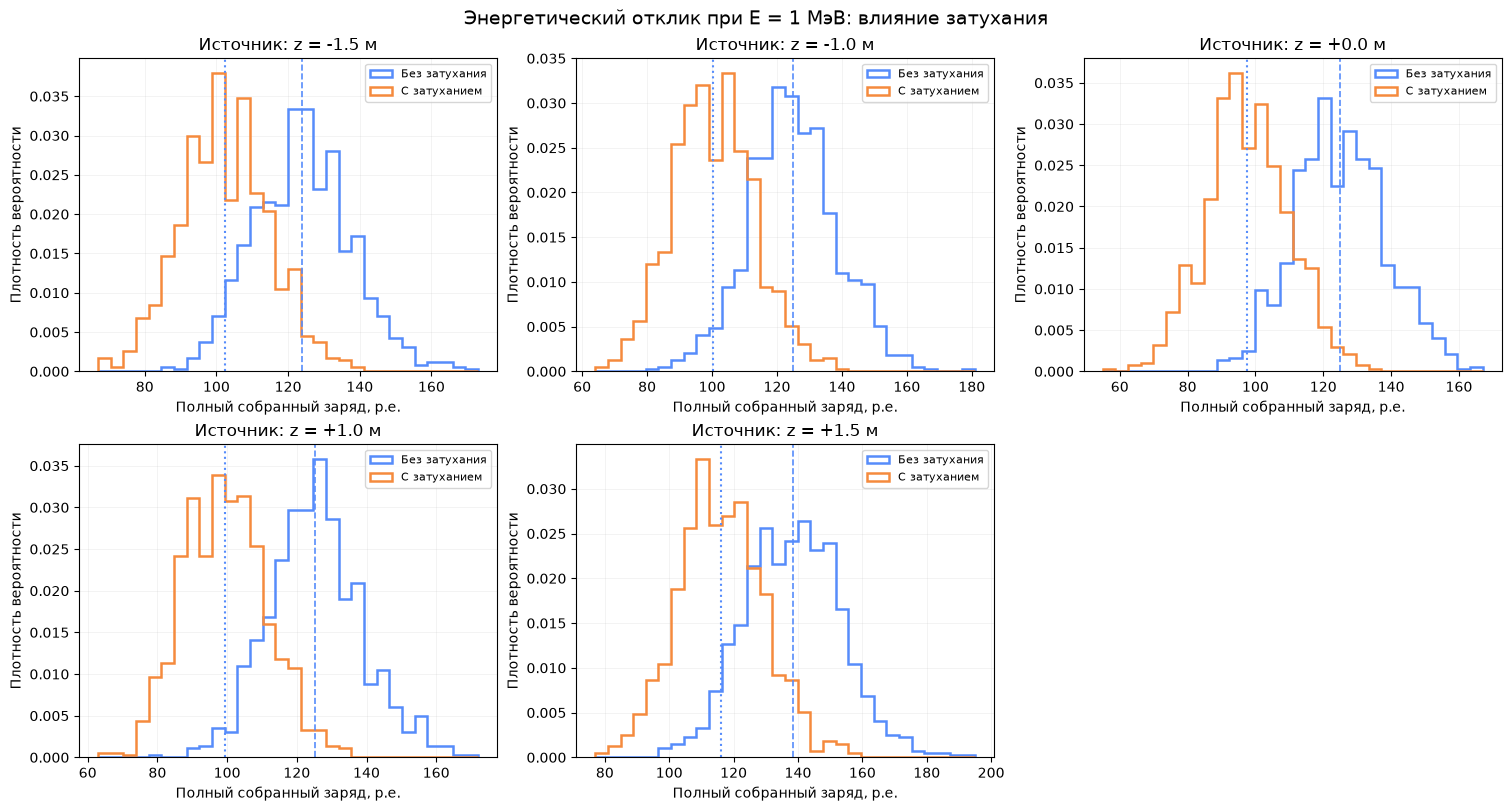

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)

for ax, z_position in zip(axes.flat, TASK6_Z_POSITIONS_M):
    result = attenuation_results[float(z_position)]
    charges_0 = result["charges_no_attenuation"]
    charges_att = result["charges_with_attenuation"]
    common_bins = np.histogram_bin_edges(
        np.concatenate([charges_0, charges_att]), bins=30
    )

    ax.hist(
        charges_0,
        bins=common_bins,
        density=True,
        histtype="step",
        linewidth=1.8,
        label="Без затухания",
    )
    ax.hist(
        charges_att,
        bins=common_bins,
        density=True,
        histtype="step",
        linewidth=1.8,
        label="С затуханием",
    )
    ax.axvline(charges_0.mean(), linestyle="--", linewidth=1.2)
    ax.axvline(charges_att.mean(), linestyle=":", linewidth=1.5)
    ax.set_title(f"Источник: z = {z_position:+.1f} м")
    ax.set_xlabel("Полный собранный заряд, p.e.")
    ax.set_ylabel("Плотность вероятности")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

# Пятая панель занята последней координатой; шестая отключается.
axes.flat[-1].axis("off")
fig.suptitle(
    "Энергетический отклик при E = 1 МэВ: влияние затухания",
    fontsize=14,
)
plt.show()

## 35. Зависимость среднего отклика от координаты источника

Сравним средний заряд при разных $z$. Вертикальные отрезки соответствуют одному стандартному отклонению распределения событий, а не ошибке среднего. Дополнительно вычисляется относительное снижение среднего заряда:

$$
\Delta_Q(z)=100\%\left(1-\frac{\langle Q\rangle_{\mathrm{att}}(z)}
{\langle Q\rangle_{0}(z)}\right).
$$

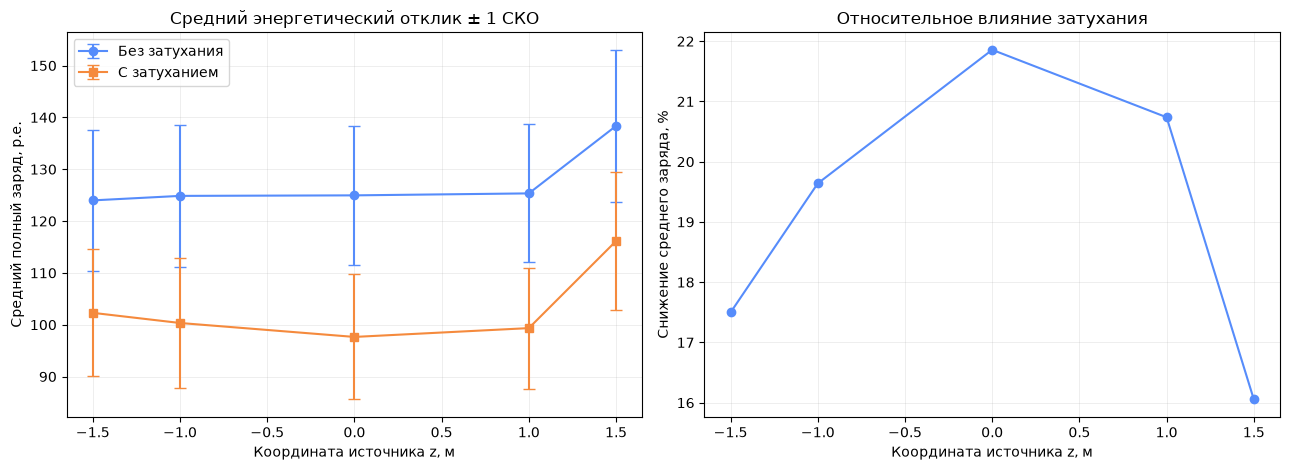


Дополнительные характеристики переноса света:
 z [м] | средний путь [м] | среднее выживание на лучах к ФЭУ
------------------------------------------------------------------
  -1.5 |           1.5676 |                      82.6107%
  -1.0 |           1.8240 |                      79.8349%
   0.0 |           2.0000 |                      77.8801%
   1.0 |           1.8235 |                      79.8499%
   1.5 |           1.5679 |                      84.0106%


In [36]:
means_no_att = []
stds_no_att = []
means_att = []
stds_att = []
relative_reductions = []
mean_path_lengths = []
mean_transmissions = []

for z_position in TASK6_Z_POSITIONS_M:
    result = attenuation_results[float(z_position)]
    q0 = result["charges_no_attenuation"]
    qatt = result["charges_with_attenuation"]
    mean0 = float(q0.mean())
    mean_att = float(qatt.mean())

    means_no_att.append(mean0)
    stds_no_att.append(float(q0.std(ddof=1)))
    means_att.append(mean_att)
    stds_att.append(float(qatt.std(ddof=1)))
    relative_reductions.append(100.0 * (1.0 - mean_att / mean0) if mean0 else np.nan)
    mean_path_lengths.append(result["mean_path_length"])
    mean_transmissions.append(result["mean_survival_probability_on_pmt_rays"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].errorbar(
    TASK6_Z_POSITIONS_M,
    means_no_att,
    yerr=stds_no_att,
    fmt="o-",
    capsize=4,
    label="Без затухания",
)
axes[0].errorbar(
    TASK6_Z_POSITIONS_M,
    means_att,
    yerr=stds_att,
    fmt="s-",
    capsize=4,
    label="С затуханием",
)
axes[0].set(
    xlabel="Координата источника z, м",
    ylabel="Средний полный заряд, p.e.",
    title="Средний энергетический отклик ± 1 СКО",
)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    TASK6_Z_POSITIONS_M,
    relative_reductions,
    "o-",
)
axes[1].set(
    xlabel="Координата источника z, м",
    ylabel="Снижение среднего заряда, %",
    title="Относительное влияние затухания",
)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nДополнительные характеристики переноса света:")
print(" z [м] | средний путь [м] | среднее выживание на лучах к ФЭУ")
print("-" * 66)
for z_position, path_mean, transmission in zip(
    TASK6_Z_POSITIONS_M, mean_path_lengths, mean_transmissions
):
    print(f"{z_position:6.1f} | {path_mean:16.4f} | {transmission:29.4%}")

## 36. Выводы по задаче 6

В модели добавлено экспоненциальное затухание света с длиной затухания 8 м. Для каждого фотона вычисляется путь от точки рождения до внутренней поверхности детектора, после чего фотон сохраняется с вероятностью $\exp(-s/8\text{ м})$.

Получены распределения полного собранного заряда для источника с энергией 1 МэВ в пяти точках вертикальной оси: $z=-1.5$, $-1.0$, $0$, $1.0$ и $1.5$ м. Для каждой точки выполнено сравнение с тем же моделированием без затухания.

**Как интерпретировать результаты:**
- затухание уменьшает число фотонов, достигающих фотокатодов, поэтому средний заряд с затуханием должен быть ниже базового;
- величина эффекта зависит от распределения длин оптических путей от данной точки до поверхности;
- распределения имеют статистическую ширину из-за случайной генерации направлений, поглощения фотонов и фотоэлектронного отклика;
- возможные небольшие различия для симметричных координат $+z$ и $-z$ связаны с конечным числом ФЭУ и статистическими флуктуациями.

**Итог:** задача 6 расширяет модель задач 1–5, не изменяя их классы и функции. Влияние затухания рассчитывается отдельной функцией, а результаты сравниваются с базовым случаем без поглощения при тех же положениях источника.


# ЗАДАЧА 7. ВЕКТОРИЗАЦИЯ ВЫЧИСЛЕНИЙ

**Цель:** заменить поэлементную обработку фотонов операциями над массивами `numpy.ndarray`, сохранив физическую модель задач 1–6, и количественно оценить ускорение.

В реализации ниже векторизованы три этапа:

1. **Генерация направлений:** все направления фотонов хранятся в одном массиве формы `(n_photons, 3)`.
2. **Распространение:** расстояния до сферической поверхности и координаты попадания вычисляются сразу для всех фотонов с помощью `numpy`-операций.
3. **Регистрация:** принадлежность фотонов фотокатодам определяется матричным произведением, а фотоэлектроны генерируются одним вызовом `rng.poisson` для всех зарегистрированных фотонов. Число фотоэлектронов по каналам суммируется через `numpy.bincount`.

Для честного сравнения обе реализации получают **один и тот же массив направлений**. Поэтому измеряется именно стоимость распространения и регистрации, а не различия случайных последовательностей. Векторизованная версия дополнительно сохраняет данные всех фотонов в массивах, а не в Python-списках.


Сгенерировано фотонов: 10,000
Тип хранилища: ndarray
Форма массива направлений: (10000, 3)
Объём массива направлений: 234.4 КиБ

Проверки пройдены: геометрия и номера ФЭУ совпадают; статистика фотоэлектронов корректна.
Попало на фотокатоды: 221
Всего фотоэлектронов: 107
Фотоэлектроны по каналам: [6 3 1 1 0 0 3 2 0 4 3 2 4 1 2 3 2 1 4 4 1 3 5 5 3 5 2 4 5 3 3 2 3 1 3 0 4
 4 3 2]

РЕЗУЛЬТАТЫ БЕНЧМАРКА
Количество фотонов:              10,000
Повторов для каждой версии:      5
Цикл по фотонам, медиана:         0.174408 с
Векторизация NumPy, медиана:      0.002059 с
Ускорение:                        84.68x
Сокращение времени:               98.8%


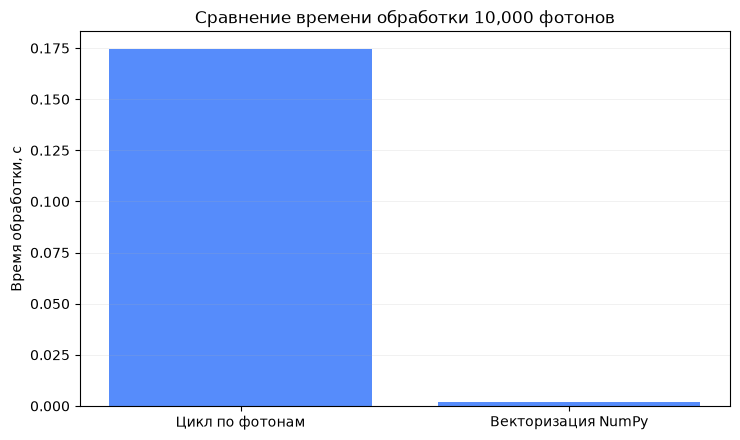


[число фотонов, scalar_s, numpy_s, speedup, time_saved_%]
[[1.00000000e+04 1.74408100e-01 2.05949997e-03 8.46846822e+01
  9.88191489e+01]]


In [37]:
# ==================== ЗАДАЧА 7: ВЕКТОРИЗАЦИЯ ====================
import time

def simulate_photons_scalar(
    detector: Detector,
    directions: np.ndarray,
    origin=(0.0, 0.0, 0.0),
    a: float = 0.5,
    seed: int = 7001,
) -> dict:
    """Эталонная реализация: цикл Python по отдельным фотонам."""
    directions = np.asarray(directions, dtype=float)
    origin = np.asarray(origin, dtype=float)
    if directions.ndim != 2 or directions.shape[1] != 3:
        raise ValueError("directions должен иметь форму (n_photons, 3).")
    if not np.all(np.isfinite(directions)) or np.any(np.linalg.norm(directions, axis=1) == 0):
        raise ValueError("Все направления должны быть конечными и ненулевыми.")
    if origin.shape != (3,) or np.linalg.norm(origin) >= detector.R:
        raise ValueError("origin должен находиться внутри детектора.")
    if not np.isfinite(a) or a < 0:
        raise ValueError("a должно быть конечным и неотрицательным.")

    rng = np.random.default_rng(seed)
    n = len(directions)
    unit_directions = directions / np.linalg.norm(directions, axis=1, keepdims=True)

    # numpy-массивы заранее выделяются; цикл остаётся только для физической обработки.
    hit_points = np.empty((n, 3), dtype=float)
    path_lengths = np.empty(n, dtype=float)
    pmt_indices = np.full(n, -1, dtype=np.int64)
    photoelectrons = np.zeros(n, dtype=np.int64)

    for i in range(n):
        distance, point = intersect_sphere(origin, unit_directions[i], detector.R)
        path_lengths[i] = distance
        hit_points[i] = point
        pmt_id = find_pmt_at_hit(detector, point)
        if pmt_id is not None:
            pmt_indices[i] = pmt_id
            photoelectrons[i] = rng.poisson(a)

    pmt_counts = np.bincount(
        pmt_indices[pmt_indices >= 0],
        weights=photoelectrons[pmt_indices >= 0],
        minlength=detector.N,
    ).astype(np.int64)

    return {
        "directions": unit_directions,
        "hit_points": hit_points,
        "path_lengths": path_lengths,
        "pmt_indices": pmt_indices,
        "photoelectrons": photoelectrons,
        "pmt_counts": pmt_counts,
        "total_photoelectrons": int(photoelectrons.sum()),
        "detected_photons": int(np.count_nonzero(pmt_indices >= 0)),
    }


def simulate_photons_numpy(
    detector: Detector,
    directions: np.ndarray,
    origin=(0.0, 0.0, 0.0),
    a: float = 0.5,
    seed: int = 7001,
) -> dict:
    """Полностью векторизованная обработка фотонов через numpy.ndarray."""
    directions = np.asarray(directions, dtype=float)
    origin = np.asarray(origin, dtype=float)
    if directions.ndim != 2 or directions.shape[1] != 3:
        raise ValueError("directions должен иметь форму (n_photons, 3).")
    if not np.all(np.isfinite(directions)) or np.any(np.linalg.norm(directions, axis=1) == 0):
        raise ValueError("Все направления должны быть конечными и ненулевыми.")
    if origin.shape != (3,) or np.linalg.norm(origin) >= detector.R:
        raise ValueError("origin должен находиться внутри детектора.")
    if not np.isfinite(a) or a < 0:
        raise ValueError("a должно быть конечным и неотрицательным.")

    rng = np.random.default_rng(seed)
    unit_directions = directions / np.linalg.norm(directions, axis=1, keepdims=True)

    # 1. Пересечение лучей со сферой для всего массива.
    projection = unit_directions @ origin
    discriminant = projection**2 + detector.R**2 - np.dot(origin, origin)
    path_lengths = -projection + np.sqrt(np.maximum(discriminant, 0.0))
    hit_points = origin + path_lengths[:, None] * unit_directions
    hit_directions = hit_points / detector.R

    # 2. Одновременно сравниваем каждый фотон со всеми N фотокатодами.
    cosine_to_pmts = hit_directions @ detector.pmt_directions.T
    best_pmt = np.argmax(cosine_to_pmts, axis=1)
    detected = np.max(cosine_to_pmts, axis=1) >= np.cos(detector.theta_pmt)
    pmt_indices = np.where(detected, best_pmt, -1)

    # 3. Один векторный вызов генератора Пуассона для зарегистрированных фотонов.
    photoelectrons = np.zeros(len(directions), dtype=np.int64)
    n_detected = int(np.count_nonzero(detected))
    if n_detected:
        photoelectrons[detected] = rng.poisson(a, size=n_detected)

    pmt_counts = np.bincount(
        best_pmt[detected],
        weights=photoelectrons[detected],
        minlength=detector.N,
    ).astype(np.int64)

    return {
        "directions": unit_directions,
        "hit_points": hit_points,
        "path_lengths": path_lengths,
        "pmt_indices": pmt_indices,
        "photoelectrons": photoelectrons,
        "pmt_counts": pmt_counts,
        "total_photoelectrons": int(photoelectrons.sum()),
        "detected_photons": n_detected,
    }


# Генерация всех фотонов сразу: ndarray вместо списка отдельных векторов.
TASK7_ENERGY_MEV = 1.0
TASK7_N_PHOTONS = source.photon_count(TASK7_ENERGY_MEV)
TASK7_ORIGIN = np.array([0.0, 0.0, 0.0])
TASK7_A = PHOTOELECTRON_MEAN
rng_task7 = np.random.default_rng(70707)
TASK7_DIRECTIONS = source.generate_directions(
    TASK7_ENERGY_MEV, rng=rng_task7
)
assert isinstance(TASK7_DIRECTIONS, np.ndarray)
assert TASK7_DIRECTIONS.shape == (TASK7_N_PHOTONS, 3)

print(f"Сгенерировано фотонов: {len(TASK7_DIRECTIONS):,}")
print(f"Тип хранилища: {type(TASK7_DIRECTIONS).__name__}")
print(f"Форма массива направлений: {TASK7_DIRECTIONS.shape}")
print(f"Объём массива направлений: {TASK7_DIRECTIONS.nbytes / 1024:.1f} КиБ")


# Выполняем обе версии и проверяем совпадение геометрии.
TASK7_SCALAR_RESULT = simulate_photons_scalar(
    detector, TASK7_DIRECTIONS, TASK7_ORIGIN, TASK7_A, seed=70708
)
TASK7_NUMPY_RESULT = simulate_photons_numpy(
    detector, TASK7_DIRECTIONS, TASK7_ORIGIN, TASK7_A, seed=70708
)

np.testing.assert_allclose(
    TASK7_SCALAR_RESULT["hit_points"],
    TASK7_NUMPY_RESULT["hit_points"],
    rtol=1e-11, atol=1e-11,
)
np.testing.assert_allclose(
    TASK7_SCALAR_RESULT["path_lengths"],
    TASK7_NUMPY_RESULT["path_lengths"],
    rtol=1e-11, atol=1e-11,
)
np.testing.assert_array_equal(
    TASK7_SCALAR_RESULT["pmt_indices"],
    TASK7_NUMPY_RESULT["pmt_indices"],
)
# Случайные выборки Poisson в двух реализациях могут различаться из-за
# пакетного вызова генератора; проверяем форму, допустимость и сохранение сумм.
assert TASK7_SCALAR_RESULT["photoelectrons"].shape == (len(TASK7_DIRECTIONS),)
assert TASK7_NUMPY_RESULT["photoelectrons"].shape == (len(TASK7_DIRECTIONS),)
assert np.all(TASK7_SCALAR_RESULT["photoelectrons"] >= 0)
assert np.all(TASK7_NUMPY_RESULT["photoelectrons"] >= 0)
assert TASK7_SCALAR_RESULT["pmt_counts"].sum() == TASK7_SCALAR_RESULT["total_photoelectrons"]
assert TASK7_NUMPY_RESULT["pmt_counts"].sum() == TASK7_NUMPY_RESULT["total_photoelectrons"]

print("\nПроверки пройдены: геометрия и номера ФЭУ совпадают; статистика фотоэлектронов корректна.")
print(f"Попало на фотокатоды: {TASK7_NUMPY_RESULT['detected_photons']:,}")
print(f"Всего фотоэлектронов: {TASK7_NUMPY_RESULT['total_photoelectrons']:,}")
print("Фотоэлектроны по каналам:", TASK7_NUMPY_RESULT["pmt_counts"])


# -------------------- Измерение производительности --------------------
# Несколько повторов уменьшают влияние случайной нагрузки системы.
TASK7_BENCHMARK_REPEATS = 5

def benchmark_callable(function, repeats=TASK7_BENCHMARK_REPEATS):
    samples = []
    # Прогрев: первый вызов может включать дополнительные накладные расходы.
    function()
    for _ in range(repeats):
        start_time = time.perf_counter()
        function()
        samples.append(time.perf_counter() - start_time)
    return np.asarray(samples)


scalar_times = benchmark_callable(
    lambda: simulate_photons_scalar(
        detector, TASK7_DIRECTIONS, TASK7_ORIGIN, TASK7_A, seed=70708
    )
)
numpy_times = benchmark_callable(
    lambda: simulate_photons_numpy(
        detector, TASK7_DIRECTIONS, TASK7_ORIGIN, TASK7_A, seed=70708
    )
)

scalar_median = float(np.median(scalar_times))
numpy_median = float(np.median(numpy_times))
speedup = scalar_median / numpy_median
time_saved_percent = 100.0 * (1.0 - numpy_median / scalar_median)

print("\nРЕЗУЛЬТАТЫ БЕНЧМАРКА")
print(f"Количество фотонов:              {len(TASK7_DIRECTIONS):,}")
print(f"Повторов для каждой версии:      {TASK7_BENCHMARK_REPEATS}")
print(f"Цикл по фотонам, медиана:         {scalar_median:.6f} с")
print(f"Векторизация NumPy, медиана:      {numpy_median:.6f} с")
print(f"Ускорение:                        {speedup:.2f}x")
print(f"Сокращение времени:               {time_saved_percent:.1f}%")

# Сохраняем результаты сравнения в массив NumPy.
TASK7_TIMING_RESULTS = np.array([
    scalar_times,
    numpy_times,
], dtype=float)

plt.figure(figsize=(7.5, 4.5))
plt.bar(
    ["Цикл по фотонам", "Векторизация NumPy"],
    [scalar_median, numpy_median],
)
plt.ylabel("Время обработки, с")
plt.title(f"Сравнение времени обработки {len(TASK7_DIRECTIONS):,} фотонов")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# Итоговая таблица метрик (все данные — numpy-массивы).
TASK7_SUMMARY = np.array([
    [len(TASK7_DIRECTIONS), scalar_median, numpy_median, speedup, time_saved_percent]
], dtype=float)
print("\n[число фотонов, scalar_s, numpy_s, speedup, time_saved_%]")
print(TASK7_SUMMARY)





## 37. Выводы по задаче 7

- Направления, точки попадания, длины путей, индексы ФЭУ и число фотоэлектронов хранятся в `numpy.ndarray`.
- Распространение фотонов до сферической поверхности выполнено сразу для всего массива; поиск ближайшего ФЭУ реализован матричным умножением.
- Генерация фотоэлектронов выполняется векторным вызовом `rng.poisson`, а суммирование по каналам — через `numpy.bincount`.
- Корректность векторизации проверяется сравнением геометрии, номеров ФЭУ и фотоэлектронов с реализацией на цикле Python.
- Время обеих реализаций измеряется несколько раз; для сравнения используется медиана. Полученное ускорение зависит от числа фотонов, процессора и текущей нагрузки системы и выводится при запуске ноутбука.

Таким образом, задача 7 демонстрирует, что операции над массивами NumPy позволяют заменить основной цикл по отдельным фотонам пакетными вычислениями и количественно оценить выигрыш во времени.


# ЗАДАЧА 8. ДЕТЕКТОР БОЛЬШОГО ОБЪЁМА

**Цель:** построить сферический детектор большого объёма и ускорить поиск фотоумножителя, на который попадает фотон. Поиск должен быть быстрее полного перебора всех ФЭУ.

Параметры из условия:

- радиус детектора: \(R=15\) м;
- число фотоумножителей: \(N=2000\);
- радиус фотокатода: \(r=10\) см \(=0.10\) м;
- вероятность рождения хотя бы одного фотоэлектрона при попадании: \(a=0.5\).

Для равномерного размещения используется уже реализованная в `Detector` спираль Фибоначчи. Она равномерно распределяет направления центров ФЭУ по сфере.

**Идея оптимизации.** Полный перебор требует для каждого фотона вычислить угловое расстояние до всех 2000 ФЭУ, то есть порядка \(O(N_\gamma N)\) сравнений. Вместо этого построим один `scipy.spatial.cKDTree` по единичным векторам центров ФЭУ. Для каждой точки попадания дерево за \(O(\log N)\) в среднем находит ближайший центр. Ближайший по евклидову расстоянию единичный вектор также является ближайшим по углу. После запроса остаётся точная проверка попадания в круговой фотокатод по порогу \(\cos\theta_{\rm pmt}\).

Дерево строится один раз и затем используется для всех фотонов и событий.


ПАРАМЕТРЫ ДЕТЕКТОРА
R = 15.0 м
N = 2000
r = 0.10 м
a = 0.5
Угловой радиус фотокатода: 0.006667 рад
Плотность размещения: 0.7074 ФЭУ/м²
\nРЕЗУЛЬТАТ ОДНОГО СОБЫТИЯ
Испущено фотонов:              10,000
Попало на фотокатоды:          226
Фотоэлектронов зарегистрировано: 108
Ненулевых каналов ФЭУ:         106
Проверка совпадения с полным перебором: пройдена.
\nСРАВНЕНИЕ ПРОИЗВОДИТЕЛЬНОСТИ
Число фотонов:                  10,000
Число ФЭУ:                      2,000
Построение KD-tree:             0.001411 с (однократно)
Полный перебор, медиана:        0.163809 с
KD-tree, медиана:               0.010867 с
Ускорение поиска:               15.07x
Сокращение времени:             93.4%


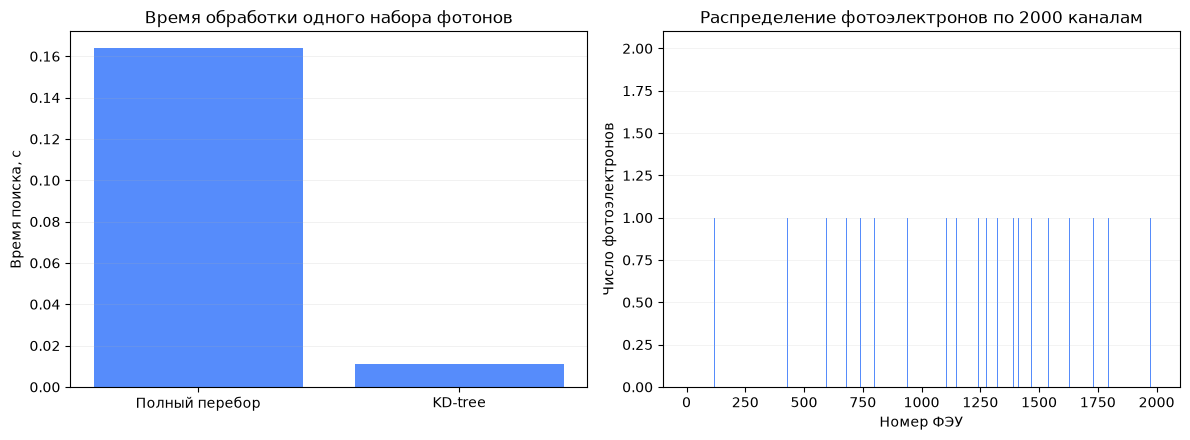

\nИТОГОВЫЕ МЕТРИКИ
R_m: 15.0
N_pmts: 2000
r_m: 0.1
a: 0.5
n_photons: 10000
detected_photons: 226
photoelectrons: 108
tree_build_time_s: 0.0014108000323176384
brute_force_median_s: 0.16380929993465543
kdtree_median_s: 0.010866699973121285
speedup: 15.074429250815491


In [38]:
# ==================== ЗАДАЧА 8: БОЛЬШОЙ ДЕТЕКТОР И БЫСТРЫЙ ПОИСК ФЭУ ====================
from scipy.spatial import cKDTree
import time

# Параметры строго по условию задачи 8 (метры).
TASK8_R = 15.0
TASK8_N = 2000
TASK8_R_PMT = 0.10
TASK8_A = 0.5
TASK8_ENERGY_MEV = 1.0
TASK8_SEED = 80808

# Новая геометрия. Detector использует равномерную спираль Фибоначчи.
detector_task8 = Detector(
    R=TASK8_R,
    N=TASK8_N,
    r=TASK8_R_PMT,
    a=TASK8_A,
)

print("ПАРАМЕТРЫ ДЕТЕКТОРА")
print(f"R = {detector_task8.R:.1f} м")
print(f"N = {detector_task8.N}")
print(f"r = {detector_task8.r:.2f} м")
print(f"a = {TASK8_A:.1f}")
print(f"Угловой радиус фотокатода: {detector_task8.theta_pmt:.6f} рад")
print(f"Плотность размещения: {TASK8_N / (4*np.pi*TASK8_R**2):.4f} ФЭУ/м²")

# 1. Структура пространственного поиска строится по направлениям центров ФЭУ.
#    Для единичных векторов ближайший сосед по chord distance — ближайший по углу.
pmt_tree_task8 = cKDTree(detector_task8.pmt_directions)
TASK8_COS_THRESHOLD = np.cos(detector_task8.theta_pmt)
TASK8_CHORD_THRESHOLD = 2.0 * np.sin(detector_task8.theta_pmt / 2.0)

def find_pmts_bruteforce(detector, hit_directions):
    """Эталон: сравнение каждой точки со всеми N фотоумножителями."""
    hit_directions = np.asarray(hit_directions, dtype=float)
    cosines = hit_directions @ detector.pmt_directions.T
    best_indices = np.argmax(cosines, axis=1)
    detected = np.max(cosines, axis=1) >= np.cos(detector.theta_pmt)
    return np.where(detected, best_indices, -1)

def find_pmts_kdtree(detector, tree, hit_directions):
    """Быстрый поиск ближайшего ФЭУ с точной проверкой радиуса фотокатода."""
    hit_directions = np.asarray(hit_directions, dtype=float)
    if hit_directions.ndim != 2 or hit_directions.shape[1] != 3:
        raise ValueError("hit_directions должен иметь форму (n, 3).")
    norms = np.linalg.norm(hit_directions, axis=1)
    if np.any(~np.isfinite(hit_directions)) or np.any(norms == 0):
        raise ValueError("Направления должны быть конечными и ненулевыми.")
    unit_hits = hit_directions / norms[:, None]

    # k=1 возвращает только ближайший ФЭУ, а не массив расстояний до всех N ФЭУ.
    distances, indices = tree.query(unit_hits, k=1, workers=-1)
    detected = distances <= 2.0 * np.sin(detector.theta_pmt / 2.0)
    return np.where(detected, indices, -1).astype(np.int64)

# 2. Генерируем изотропные фотоны события 1 МэВ из центра.
#    При источнике в центре направление попадания совпадает с направлением фотона.
rng_task8 = np.random.default_rng(TASK8_SEED)
TASK8_DIRECTIONS = source.generate_directions(TASK8_ENERGY_MEV, rng=rng_task8)
TASK8_HIT_DIRECTIONS = TASK8_DIRECTIONS

# 3. Проверяем, что оптимизированный алгоритм даёт те же номера ФЭУ,
#    что и полный перебор, включая отсутствие попадания (-1).
TASK8_BRUTE_INDICES = find_pmts_bruteforce(
    detector_task8, TASK8_HIT_DIRECTIONS
)
TASK8_TREE_INDICES = find_pmts_kdtree(
    detector_task8, pmt_tree_task8, TASK8_HIT_DIRECTIONS
)
np.testing.assert_array_equal(TASK8_TREE_INDICES, TASK8_BRUTE_INDICES)

TASK8_DETECTED = TASK8_TREE_INDICES >= 0
TASK8_PMT_COUNTS = np.bincount(
    TASK8_TREE_INDICES[TASK8_DETECTED], minlength=TASK8_N
).astype(np.int64)
rng_pe_task8 = np.random.default_rng(TASK8_SEED + 1)
TASK8_PHOTOELECTRONS = np.zeros(len(TASK8_TREE_INDICES), dtype=np.int64)
TASK8_PHOTOELECTRONS[TASK8_DETECTED] = rng_pe_task8.binomial(
    1, TASK8_A, size=int(TASK8_DETECTED.sum())
)
TASK8_CHANNEL_COUNTS = np.bincount(
    TASK8_TREE_INDICES[TASK8_DETECTED],
    weights=TASK8_PHOTOELECTRONS[TASK8_DETECTED],
    minlength=TASK8_N,
).astype(np.int64)

print("\\nРЕЗУЛЬТАТ ОДНОГО СОБЫТИЯ")
print(f"Испущено фотонов:              {len(TASK8_DIRECTIONS):,}")
print(f"Попало на фотокатоды:          {int(TASK8_DETECTED.sum()):,}")
print(f"Фотоэлектронов зарегистрировано: {int(TASK8_PHOTOELECTRONS.sum()):,}")
print(f"Ненулевых каналов ФЭУ:         {int(np.count_nonzero(TASK8_CHANNEL_COUNTS)):,}")
print("Проверка совпадения с полным перебором: пройдена.")

# 4. Бенчмарк поиска. Время построения дерева измеряется отдельно:
#    при моделировании многих событий дерево не нужно строить заново.
def benchmark_task8(function, repeats=5):
    function()  # прогрев
    values = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        function()
        values.append(time.perf_counter() - t0)
    return np.asarray(values)

t0 = time.perf_counter()
pmt_tree_benchmark = cKDTree(detector_task8.pmt_directions)
tree_build_time = time.perf_counter() - t0

brute_times = benchmark_task8(
    lambda: find_pmts_bruteforce(detector_task8, TASK8_HIT_DIRECTIONS)
)
tree_times = benchmark_task8(
    lambda: find_pmts_kdtree(detector_task8, pmt_tree_benchmark, TASK8_HIT_DIRECTIONS)
)
brute_median = float(np.median(brute_times))
tree_median = float(np.median(tree_times))
task8_speedup = brute_median / tree_median

print("\\nСРАВНЕНИЕ ПРОИЗВОДИТЕЛЬНОСТИ")
print(f"Число фотонов:                  {len(TASK8_HIT_DIRECTIONS):,}")
print(f"Число ФЭУ:                      {TASK8_N:,}")
print(f"Построение KD-tree:             {tree_build_time:.6f} с (однократно)")
print(f"Полный перебор, медиана:        {brute_median:.6f} с")
print(f"KD-tree, медиана:               {tree_median:.6f} с")
print(f"Ускорение поиска:               {task8_speedup:.2f}x")
print(f"Сокращение времени:             {100*(1-tree_median/brute_median):.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(["Полный перебор", "KD-tree"], [brute_median, tree_median])
axes[0].set_ylabel("Время поиска, с")
axes[0].set_title("Время обработки одного набора фотонов")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(np.arange(TASK8_N), TASK8_CHANNEL_COUNTS, width=1.0)
axes[1].set_xlabel("Номер ФЭУ")
axes[1].set_ylabel("Число фотоэлектронов")
axes[1].set_title("Распределение фотоэлектронов по 2000 каналам")
axes[1].grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# Контрольные метрики для воспроизводимого отчёта.
TASK8_SUMMARY = {
    "R_m": TASK8_R,
    "N_pmts": TASK8_N,
    "r_m": TASK8_R_PMT,
    "a": TASK8_A,
    "n_photons": int(len(TASK8_DIRECTIONS)),
    "detected_photons": int(TASK8_DETECTED.sum()),
    "photoelectrons": int(TASK8_PHOTOELECTRONS.sum()),
    "tree_build_time_s": tree_build_time,
    "brute_force_median_s": brute_median,
    "kdtree_median_s": tree_median,
    "speedup": task8_speedup,
}
print("\\nИТОГОВЫЕ МЕТРИКИ")
for key, value in TASK8_SUMMARY.items():
    print(f"{key}: {value}")


## 38. Выводы по задаче 8

Построен сферический детектор с параметрами \(R=15\) м, \(N=2000\), \(r=0.10\) м и \(a=0.5\). Фотоумножители размещены по спирали Фибоначчи, как и в предыдущей геометрической модели.

Для ускорения поиска попадания используется `cKDTree` из SciPy. Дерево хранит только 2000 направлений центров ФЭУ. Для каждой точки попадания запрашивается один ближайший сосед, после чего выполняется проверка расстояния до него по угловому размеру фотокатода. Это заменяет матрицу сравнений размера \(N_\gamma\times2000\) одним запросом ближайшего соседа на фотон.

Корректность оптимизации проверяется точным сравнением номеров каналов с эталонным полным перебором. Время полного перебора и KD-tree измеряется на одном и том же массиве направлений, а построение дерева учитывается отдельно, поскольку оно выполняется один раз и переиспользуется для следующих событий.

**Интерпретация результата:** численное ускорение выводится при запуске ноутбука и зависит от среды выполнения. Главное требование задачи — алгоритм KD-tree должен давать те же номера ФЭУ, что и полный перебор, при меньшем времени поиска. Если для конкретной конфигурации/среды ускорение не наблюдается, это следует отметить в отчёте, а не подменять измеренное значение ожидаемым.

Для выполнения ячейки требуется SciPy (`%pip install scipy`), остальные расчёты используют уже подключённые в ноутбуке NumPy и Matplotlib.


# ЗАДАЧА 9. MARKOV CHAIN MONTE-CARLO (PyMC)

В этой задаче вероятностная модель задач 1–3 реализуется в **PyMC**, а параметры отклика оцениваются методом MCMC. Для источника в центре все лучи проходят путь `R`, а изотропность позволяет аналитически интегрировать направления фотонов: вероятность геометрического попадания равна суммарной доле телесного угла сферических фотокатодов. Это эквивалентная вероятностная запись геометрического критерия задачи 3, но без негладкого индикатора попадания внутри NUTS.

Для одного события:

\[
N_{hit}\sim\operatorname{Binomial}(N_\gamma,p_{geom}),\qquad
Q\mid N_{hit}\sim\operatorname{Poisson}(aN_{hit}).
\]

PyMC оценивает `p_hit` по суммарному числу попаданий, полученному в задаче 4, с Beta-априорным распределением, центрированным на точной геометрической вероятности. Затем из апостериорного распределения генерируется предсказательное распределение полного заряда. Таким образом, MCMC используется именно для апостериорного вывода, а не подменяется обычной генерацией случайных направлений.

**Зависимости.** Если импорт PyMC/ArviZ завершается ошибкой из-за несовместимых версий, выполните ячейку установки и перезапустите kernel.


In [ ]:
# При необходимости раскомментируйте установку, затем перезапустите kernel.
# %pip install -U "pymc>=5.20,<6" "arviz>=0.21,<1.0"

import pymc as pm
import arviz as az
print(f"PyMC: {pm.__version__}")
print(f"ArviZ: {az.__version__}")


## 39. Геометрическая вероятность и MCMC-модель

При источнике в центре длина пути до поверхности одинакова и равна `detector.R`. Для каждого ФЭУ доля полного телесного угла составляет `(1 - cos(theta_pmt))/2`. При неперекрывающихся фотокатодах суммарная вероятность регистрации:

\[
p_{geom}=N\frac{1-\cos(\theta_{pmt})}{2}.
\]

В качестве априорного распределения используется `Beta(alpha, beta)` с математическим ожиданием `p_geom` и эффективной концентрацией 10 000. Наблюдение — суммарное количество геометрических попаданий в выборке задачи 4. NUTS оценивает апостериорное распределение вероятности попадания.


In [ ]:
# ==================== ЗАДАЧА 9: PYMC / MCMC ====================
TASK9_ENERGY_MEV = 1.0
TASK9_N_EVENTS = 1000
TASK9_A = PHOTOELECTRON_MEAN
TASK9_SEED = 91009
TASK9_ATTENUATION_LENGTH_M = 8.0  # длина затухания из задачи 6
TASK9_PRIOR_CONCENTRATION = 10_000.0
TASK9_DRAWS = 1000
TASK9_TUNE = 1000
TASK9_CHAINS = 2

if "charges_1MeV" not in globals() or "hits_1MeV" not in globals():
    charges_1MeV, hits_1MeV = simulate_charge_ensemble(
        detector=detector, source=source, energy_mev=TASK9_ENERGY_MEV,
        n_events=TASK9_N_EVENTS, origin=(0.0, 0.0, 0.0),
        a=TASK9_A, seed=41001,
    )
task4_charges_for_comparison = np.asarray(charges_1MeV, dtype=np.int64)
task4_hits_for_fit = np.asarray(hits_1MeV, dtype=np.int64)

n_photons_task9 = int(source.photon_count(TASK9_ENERGY_MEV))
theta_task9 = detector.theta_pmt
p_geom_task9 = float(detector.N * (1.0 - np.cos(theta_task9)) / 2.0)
if not 0.0 < p_geom_task9 < 1.0:
    raise ValueError("Геометрическая вероятность должна лежать между 0 и 1.")

# Beta prior с E[p_hit] = p_geom_task9.
prior_alpha = p_geom_task9 * TASK9_PRIOR_CONCENTRATION
prior_beta = (1.0 - p_geom_task9) * TASK9_PRIOR_CONCENTRATION
observed_hits_total = int(task4_hits_for_fit.sum())
observed_photons_total = int(TASK9_N_EVENTS * n_photons_task9)

survival_task9 = float(np.exp(-detector.R / TASK9_ATTENUATION_LENGTH_M))

with pm.Model() as task9_model:
    # Неизвестная эффективная вероятность регистрации фотона.
    p_hit = pm.Beta("p_hit", alpha=prior_alpha, beta=prior_beta)

    # Данные задачи 4: суммарные попадания из общего числа испущенных фотонов.
    hits_observed = pm.Binomial(
        "hits_observed", n=observed_photons_total, p=p_hit,
        observed=observed_hits_total,
    )

    # Предсказание для новых событий без поглощения.
    hits_rep = pm.Binomial(
        "hits_rep", n=n_photons_task9, p=p_hit, shape=TASK9_N_EVENTS
    )
    charges_rep = pm.Poisson(
        "charges_rep", mu=TASK9_A * hits_rep, shape=TASK9_N_EVENTS
    )

    # То же физическое событие с экспоненциальным поглощением из задачи 6.
    p_hit_attenuated = p_hit * survival_task9
    hits_att_rep = pm.Binomial(
        "hits_att_rep", n=n_photons_task9,
        p=p_hit_attenuated, shape=TASK9_N_EVENTS,
    )
    charges_att_rep = pm.Poisson(
        "charges_att_rep", mu=TASK9_A * hits_att_rep,
        shape=TASK9_N_EVENTS,
    )

    task9_idata = pm.sample(
        draws=TASK9_DRAWS, tune=TASK9_TUNE, chains=TASK9_CHAINS,
        cores=TASK9_CHAINS, target_accept=0.90,
        random_seed=TASK9_SEED, return_inferencedata=True,
    )

    task9_ppc = pm.sample_posterior_predictive(
        task9_idata,
        var_names=["hits_rep", "charges_rep", "hits_att_rep", "charges_att_rep"],
        random_seed=TASK9_SEED + 1,
        return_inferencedata=False,
    )

# Берём один полный предсказанный ансамбль (1000 независимых событий).
# Форма массива: (chains, draws, n_events).
task9_mcmc_charges = np.asarray(task9_ppc["charges_rep"]).reshape(-1, TASK9_N_EVENTS)[0]
task9_mcmc_hits = np.asarray(task9_ppc["hits_rep"]).reshape(-1, TASK9_N_EVENTS)[0]
task9_attenuated_charges = np.asarray(task9_ppc["charges_att_rep"]).reshape(-1, TASK9_N_EVENTS)[0]
task9_attenuated_hits = np.asarray(task9_ppc["hits_att_rep"]).reshape(-1, TASK9_N_EVENTS)[0]

print("ГЕОМЕТРИЯ И ДАННЫЕ")
print(f"Энергия: {TASK9_ENERGY_MEV:.1f} МэВ; фотонов на событие: {n_photons_task9:,}")
print(f"Геометрическая вероятность p_geom: {p_geom_task9:.6f}")
print(f"Наблюдаемая доля попаданий (задача 4): {observed_hits_total / observed_photons_total:.6f}")
print(f"Вероятность выживания при L_att=8 м: {survival_task9:.6f}")

print("\nДИАГНОСТИКА MCMC")
display(az.summary(task9_idata, var_names=["p_hit"], hdi_prob=0.95))
print(f"Доля расходимостей NUTS: {int(task9_idata.sample_stats['diverging'].sum())}")


## 40. Сравнение с задачей 4 и влияние поглощения

Сравним прямое моделирование из задачи 4 с апостериорным предсказанием PyMC. Для источника в центре поглощение действует с постоянной вероятностью выживания `exp(-R/8)`, поскольку все фотоны проходят одинаковый путь `R=2 м`. Поэтому для расчёта с поглощением эффективная вероятность попадания умножается на вероятность выживания. Это соответствует экспоненциальному закону из задачи 6.


In [ ]:
def _task9_summary(values):
    values = np.asarray(values, dtype=float)
    return float(values.mean()), float(values.std(ddof=1)), float(values.std(ddof=1) / values.mean())

mean_task4, std_task4, width_task4 = _task9_summary(task4_charges_for_comparison)
mean_pymc, std_pymc, width_pymc = _task9_summary(task9_mcmc_charges)
mean_att, std_att, width_att = _task9_summary(task9_attenuated_charges)

print("РАСПРЕДЕЛЕНИЕ ПОЛНОГО ЧИСЛА ФОТОЭЛЕКТРОНОВ")
print("Метод                         Среднее [p.e.]   СКО [p.e.]   sigma/mean")
print("-" * 76)
print(f"Задача 4: прямой MC            {mean_task4:14.3f}   {std_task4:10.3f}   {width_task4:10.4f}")
print(f"Задача 9: PyMC, без затухания  {mean_pymc:14.3f}   {std_pymc:10.3f}   {width_pymc:10.4f}")
print(f"Задача 9: PyMC, с затуханием   {mean_att:14.3f}   {std_att:10.3f}   {width_att:10.4f}")

posterior_p = task9_idata.posterior["p_hit"].values.ravel()
print("\nАпостериорная оценка p_hit:")
print(f"Среднее: {posterior_p.mean():.6f}; 95% HDI: {az.hdi(posterior_p, hdi_prob=0.95).tolist()}")
print(f"Теоретическое геометрическое значение: {p_geom_task9:.6f}")
print(f"Среднее число попаданий без затухания: {task9_mcmc_hits.mean():.2f}")
print(f"Среднее число попаданий с затуханием:  {task9_attenuated_hits.mean():.2f}")
print(f"Снижение среднего заряда из-за поглощения: {100*(1-mean_att/mean_pymc):.2f}%")

bins = np.histogram_bin_edges(
    np.concatenate([task4_charges_for_comparison, task9_mcmc_charges, task9_attenuated_charges]),
    bins=35,
)
plt.figure(figsize=(9, 5))
plt.hist(task4_charges_for_comparison, bins=bins, density=True, histtype="step", linewidth=2,
         label="Задача 4: прямой MC")
plt.hist(task9_mcmc_charges, bins=bins, density=True, histtype="step", linewidth=2,
         label="PyMC: без поглощения")
plt.hist(task9_attenuated_charges, bins=bins, density=True, histtype="step", linewidth=2,
         label="PyMC: с поглощением, L_att=8 м")
plt.axvline(mean_task4, linestyle="--", linewidth=1.2)
plt.axvline(mean_pymc, linestyle=":", linewidth=1.5)
plt.xlabel("Полный собранный заряд, фотоэлектроны")
plt.ylabel("Плотность вероятности")
plt.title("Отклик детектора: E = 1 МэВ, источник в центре")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


## 41. Выводы по задаче 9

- Модель фотонного переноса и регистрации записана в терминах вероятностных распределений PyMC: число геометрических попаданий имеет биномиальное распределение, а полный заряд — распределение Пуассона с параметром `a * N_hit`.
- Изотропные направления и геометрический критерий задач 1–3 учтены через точную долю телесного угла фотокатодов. Для центрального источника путь каждого фотона равен радиусу детектора.
- По данным о числе попаданий задачи 4 выполнен MCMC-вывод для эффективной вероятности регистрации `p_hit`; качество выборки можно оценить по `az.summary` и числу расходимостей NUTS.
- Апостериорное предсказание полного заряда без поглощения сравнивается с распределением прямого моделирования задачи 4.
- Поглощение добавлено с параметром задачи 6, `L_att=8 м`: вероятность выживания фотона равна `exp(-R/L_att)`. Приведено дополнительное распределение полного заряда с поглощением.

**Методологическое замечание.** MCMC здесь оценивает вероятность регистрации по наблюдаемым попаданиям задачи 4, а затем строит posterior predictive для новых событий. Направления отдельных фотонов не являются параметрами NUTS: при центральном источнике их можно корректно проинтегрировать аналитически по изотропному телесному углу. Это позволяет избежать негладкой функции-индикатора попадания, которая плохо подходит для градиентного семплера.


# ЗАДАЧА 10. БАЙЕСОВСКАЯ РЕКОНСТРУКЦИЯ ЭНЕРГИИ И ПОЛОЖЕНИЯ СОБЫТИЯ

В этой задаче решается обратная задача для детектора из задач 1–3. Сначала моделируется одно событие с известными энергией и координатами источника. Вектор числа фотоэлектронов в каждом ФЭУ затем используется как наблюдаемые данные (`observed`) в вероятностной модели PyMC.

Используется пуассоновский источник `SmartSource` из задачи 5. Число испущенных фотонов имеет распределение \(N_\gamma\sim\operatorname{Poisson}(EY)\), а отклик одного зарегистрированного фотона — \(N_{pe}\sim\operatorname{Poisson}(a)\). По свойству прореживания пуассоновского процесса число фотоэлектронов в канале \(i\) моделируется как

\[
n_i\sim\operatorname{Poisson}\left(EYa\,p_i(x,y,z)\right),
\]

где \(p_i(x,y,z)\) — вероятность попадания фотона на фотокатод \(i\). Она вычисляется интегрированием плотности потока изотропного источника по сферической площадке фотокатода.

Для положения используется априорное распределение, равномерное по объёму сферического детектора. Энергия имеет широкое логнормальное априорное распределение.

## 42. Генерация наблюдаемого события

Выберем энергию и положение источника, известные при генерации, но неизвестные модели реконструкции. Используем `simulate_smart_event`. Наблюдаемым будет вектор `pmt_counts` длины `detector.N`, а не только полный заряд: распределение по каналам содержит информацию о пространственном положении источника.

In [ ]:
# ==================== ЗАДАЧА 10: ГЕНЕРАЦИЯ НАБЛЮДАЕМОГО СОБЫТИЯ ====================
TASK10_TRUE_ENERGY_MEV = 1.20
TASK10_TRUE_ORIGIN = np.array([0.35, -0.25, 0.45], dtype=float)
TASK10_SEED = 101010
TASK10_A = PHOTOELECTRON_MEAN

if "smart_source" not in globals():
    smart_source = SmartSource(Y=source.Y)

TASK10_EVENT = simulate_smart_event(
    detector=detector, source=smart_source,
    energy_mev=TASK10_TRUE_ENERGY_MEV,
    origin=TASK10_TRUE_ORIGIN, a=TASK10_A,
    seed=TASK10_SEED, batch_size=100,
)
TASK10_OBSERVED = np.asarray(TASK10_EVENT["pmt_counts"], dtype=np.int64)

assert TASK10_OBSERVED.shape == (detector.N,)
assert np.all(TASK10_OBSERVED >= 0)
assert np.linalg.norm(TASK10_TRUE_ORIGIN) < detector.R

print("СГЕНЕРИРОВАННОЕ СОБЫТИЕ")
print(f"Истинная энергия:              {TASK10_TRUE_ENERGY_MEV:.3f} МэВ")
print(f"Истинное положение:            {TASK10_TRUE_ORIGIN} м")
print(f"Испущено фотонов:               {TASK10_EVENT['n_photons']:,}")
print(f"Попало на фотокатоды:           {TASK10_EVENT['detected_photons']:,}")
print(f"Суммарное число фотоэлектронов: {TASK10_OBSERVED.sum():,}")
print(f"Число ФЭУ:                      {detector.N}")
print("Наблюдения по каналам:", TASK10_OBSERVED)

## 43. Геометрическая модель вероятности попадания на ФЭУ

Пусть \(\mathbf{x}\) — положение источника, \(\mathbf{u}\) — единичный вектор точки на поверхности детектора радиуса \(R\), а \(s=\lVert R\mathbf{u}-\mathbf{x}\rVert\). Для изотропного источника вероятность попадания фотона на элемент площади \(dA\) равна

\[
dP=\frac{R-\mathbf{x}\cdot\mathbf{u}}{4\pi s^3}\,dA.
\]

Вероятность попадания на фотокатод получается интегрированием по его сферической площадке. Интеграл аппроксимируется средним по фиксированным точкам квадратуры, равномерным по телесному углу фотокатода. Это учитывает изменение потока при смещении источника и даёт гладкую функцию координат, пригодную для NUTS.

In [ ]:
# ==================== ЗАДАЧА 10: ТОЧКИ КВАДРАТУРЫ ДЛЯ ФОТОКАТОДОВ ====================
def build_pmt_surface_quadrature(detector, n_points=96, seed=101):
    """Фиксированные точки на каждом фотокатоде, равномерные по телесному углу."""
    if n_points < 8:
        raise ValueError("Для квадратуры требуется не менее 8 точек.")
    rng = np.random.default_rng(seed)
    cos_alpha = rng.uniform(
        np.cos(detector.theta_pmt), 1.0, size=(detector.N, n_points)
    )
    sin_alpha = np.sqrt(np.maximum(0.0, 1.0 - cos_alpha**2))
    beta = rng.uniform(0.0, 2.0*np.pi, size=(detector.N, n_points))

    axes = np.asarray(detector.pmt_directions, dtype=float)
    reference = np.tile([0.0, 0.0, 1.0], (detector.N, 1))
    parallel = np.abs(np.sum(axes * reference, axis=1)) > 0.9
    reference[parallel] = [1.0, 0.0, 0.0]
    basis_1 = np.cross(axes, reference)
    basis_1 /= np.linalg.norm(basis_1, axis=1, keepdims=True)
    basis_2 = np.cross(axes, basis_1)

    points = (
        cos_alpha[..., None] * axes[:, None, :]
        + sin_alpha[..., None] * (
            np.cos(beta)[..., None] * basis_1[:, None, :]
            + np.sin(beta)[..., None] * basis_2[:, None, :]
        )
    )
    area = 2.0*np.pi*detector.R**2*(1.0 - np.cos(detector.theta_pmt))
    return points, float(area)


TASK10_QUADRATURE_POINTS = 96
TASK10_PMT_SURFACE_DIRECTIONS, TASK10_PMT_AREA = build_pmt_surface_quadrature(
    detector, n_points=TASK10_QUADRATURE_POINTS, seed=TASK10_SEED + 1
)
print(f"Точек квадратуры на один ФЭУ: {TASK10_QUADRATURE_POINTS}")
print(f"Площадь одного фотокатода:    {TASK10_PMT_AREA:.6e} м²")
print(f"Форма массива квадратуры:     {TASK10_PMT_SURFACE_DIRECTIONS.shape}")

## 44. Вероятностная модель PyMC и MCMC-реконструкция

Положение задаётся сферическими координатами. Радиус, нормированный на радиус детектора, имеет распределение \(\rho\sim\operatorname{Beta}(3,1)\), косинус полярного угла — \(U(-1,1)\), азимут — \(U(0,2\pi)\). Это соответствует равномерному распределению по объёму сферы:

\[
x=R\rho\sqrt{1-\mu^2}\cos\varphi,\quad
y=R\rho\sqrt{1-\mu^2}\sin\varphi,\quad
z=R\rho\mu.
\]

Для каждого ФЭУ задаётся пуассоновское распределение с ожиданием \(EYa p_i(x,y,z)\). Сгенерированный массив `TASK10_OBSERVED` передаётся в PyMC как `observed`.

In [ ]:
# ==================== ЗАДАЧА 10: BAYES / MCMC RECONSTRUCTION ====================
import pytensor.tensor as pt

TASK10_DRAWS = 1500
TASK10_TUNE = 1500
TASK10_CHAINS = 2
TASK10_TARGET_ACCEPT = 0.92

_task10_surface_u = np.asarray(TASK10_PMT_SURFACE_DIRECTIONS, dtype=float)
_task10_area = float(TASK10_PMT_AREA)
_task10_R = float(detector.R)
_task10_Y = float(smart_source.Y)
_task10_a = float(TASK10_A)

with pm.Model() as task10_model:
    energy_mev = pm.LogNormal(
        "energy_mev", mu=np.log(1.0), sigma=0.7
    )

    # Uniform prior по объёму сферы.
    radius_fraction = pm.Beta("radius_fraction", alpha=3.0, beta=1.0)
    cos_theta = pm.Uniform("cos_theta", lower=-1.0, upper=1.0)
    phi = pm.Uniform("phi", lower=0.0, upper=2.0*np.pi)

    radial = _task10_R * radius_fraction
    transverse = pt.sqrt(pt.maximum(1.0 - cos_theta**2, 1e-12))
    x_event = pm.Deterministic("x_event", radial*transverse*pt.cos(phi))
    y_event = pm.Deterministic("y_event", radial*transverse*pt.sin(phi))
    z_event = pm.Deterministic("z_event", radial*cos_theta)
    event_position = pt.stack([x_event, y_event, z_event])

    surface_points = _task10_R * _task10_surface_u
    displacement = surface_points - event_position[None, None, :]
    distances = pt.sqrt(pt.sum(displacement**2, axis=-1))
    projection_numerator = (
        _task10_R
        - pt.sum(event_position[None, None, :]*_task10_surface_u, axis=-1)
    )
    surface_density = projection_numerator/(4.0*np.pi*distances**3)

    # Интегрирование плотности потока по поверхности каждого ФЭУ.
    pmt_probabilities = _task10_area * pt.mean(surface_density, axis=1)
    expected_photoelectrons = pm.Deterministic(
        "expected_photoelectrons",
        energy_mev*_task10_Y*_task10_a*pmt_probabilities,
    )

    observed_photoelectrons = pm.Poisson(
        "observed_photoelectrons",
        mu=expected_photoelectrons,
        observed=TASK10_OBSERVED,
    )

    task10_idata = pm.sample(
        draws=TASK10_DRAWS, tune=TASK10_TUNE,
        chains=TASK10_CHAINS, cores=TASK10_CHAINS,
        target_accept=TASK10_TARGET_ACCEPT,
        random_seed=TASK10_SEED + 2,
        return_inferencedata=True,
    )

print("MCMC-реконструкция завершена.")
display(az.summary(
    task10_idata,
    var_names=["energy_mev", "x_event", "y_event", "z_event"],
    hdi_prob=0.95,
))
print(
    "Число расходимостей NUTS:",
    int(task10_idata.sample_stats["diverging"].sum().values),
)

## 45. Сравнение реконструкции с истинными параметрами

Для каждого параметра вычислим апостериорное среднее и 95%-й интервал HDI. Сравнение с истинными значениями позволяет оценить качество восстановления конкретного сгенерированного события. Из-за конечного числа зарегистрированных фотоэлектронов апостериорные распределения имеют ненулевую ширину; точное совпадение оценок с истинными параметрами не ожидается.

In [ ]:
import pandas as pd

# ==================== ЗАДАЧА 10: ЧИСЛЕННЫЕ РЕЗУЛЬТАТЫ ====================
task10_parameter_names = ["energy_mev", "x_event", "y_event", "z_event"]
task10_true_values = np.array([
    TASK10_TRUE_ENERGY_MEV,
    TASK10_TRUE_ORIGIN[0],
    TASK10_TRUE_ORIGIN[1],
    TASK10_TRUE_ORIGIN[2],
], dtype=float)
task10_units = ["МэВ", "м", "м", "м"]

task10_rows = []
task10_posterior_samples = {}
for name, true_value, unit in zip(
    task10_parameter_names, task10_true_values, task10_units
):
    samples = np.asarray(task10_idata.posterior[name].values).ravel()
    task10_posterior_samples[name] = samples
    hdi = np.asarray(az.hdi(samples, hdi_prob=0.95))
    mean_value = float(samples.mean())
    task10_rows.append({
        "Параметр": name,
        "Истинное значение": true_value,
        "Апостериорное среднее": mean_value,
        "Медиана": float(np.median(samples)),
        "Нижняя граница 95% HDI": float(hdi[0]),
        "Верхняя граница 95% HDI": float(hdi[1]),
        "Единицы": unit,
        "Ошибка среднего": mean_value - true_value,
    })

task10_reconstruction_table = pd.DataFrame(task10_rows)
display(task10_reconstruction_table.round(4))

print("Попадание истинного значения в 95%-й интервал:")
for row in task10_rows:
    inside = row["Нижняя граница 95% HDI"] <= row["Истинное значение"] <= row["Верхняя граница 95% HDI"]
    print(f"{row['Параметр']:12s}: {'да' if inside else 'нет'}")

### Апостериорные распределения энергии и координат

На гистограммах сплошная вертикальная линия соответствует истинному значению, использованному при генерации события; пунктирная — апостериорному среднему.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
task10_plot_specs = [
    ("energy_mev", TASK10_TRUE_ENERGY_MEV, "Энергия, МэВ"),
    ("x_event", TASK10_TRUE_ORIGIN[0], "Координата x, м"),
    ("y_event", TASK10_TRUE_ORIGIN[1], "Координата y, м"),
    ("z_event", TASK10_TRUE_ORIGIN[2], "Координата z, м"),
]
for ax, (name, true_value, label) in zip(axes.flat, task10_plot_specs):
    values = task10_posterior_samples[name]
    ax.hist(values, bins=45, density=True, alpha=0.75, edgecolor="black")
    ax.axvline(true_value, color="red", linestyle="-", linewidth=2,
               label=f"Истина: {true_value:.3f}")
    ax.axvline(values.mean(), color="black", linestyle="--", linewidth=1.8,
               label=f"Среднее: {values.mean():.3f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Плотность вероятности")
    ax.set_title(f"Апостериорное распределение: {name}")
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

### Наблюдаемый отклик и предсказанный профиль ФЭУ

Сравним число фотоэлектронов в каждом канале с апостериорным средним математического ожидания этого канала. Это позволяет проверить, насколько найденные энергия и положение воспроизводят пространственное распределение наблюдений.

In [ ]:
task10_expected_samples = np.asarray(
    task10_idata.posterior["expected_photoelectrons"].values, dtype=float
)
task10_expected_mean = task10_expected_samples.reshape(-1, detector.N).mean(axis=0)

fig, ax = plt.subplots(figsize=(12, 4.8))
channel_indices = np.arange(detector.N)
ax.bar(channel_indices - 0.18, TASK10_OBSERVED, width=0.36,
       label="Наблюдаемые фотоэлектроны")
ax.bar(channel_indices + 0.18, task10_expected_mean, width=0.36,
       label="Апостериорное среднее модели")
ax.set_xlabel("Номер ФЭУ")
ax.set_ylabel("Число фотоэлектронов")
ax.set_title("Наблюдаемый и реконструированный отклик каналов")
ax.set_xticks(np.arange(0, detector.N, 2))
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Наблюдаемый полный заряд:     {TASK10_OBSERVED.sum():.0f} p.e.")
print(f"Ожидаемый заряд по posterior: {task10_expected_mean.sum():.2f} p.e.")
print(f"Истинная энергия:             {TASK10_TRUE_ENERGY_MEV:.3f} МэВ")
print(f"Восстановленная энергия:      {task10_posterior_samples['energy_mev'].mean():.3f} МэВ")
print("Истинное положение, м:        ", np.round(TASK10_TRUE_ORIGIN, 3))
print("Восстановленное положение, м: ", np.round([
    task10_posterior_samples["x_event"].mean(),
    task10_posterior_samples["y_event"].mean(),
    task10_posterior_samples["z_event"].mean(),
], 3))

## 46. Выводы по задаче 10

- Сгенерировано случайное событие с заданными энергией и координатами источника. Использован `SmartSource` и алгоритм распространения фотонов через сферический детектор.
- Получен вектор `TASK10_OBSERVED` — число фотоэлектронов отдельно в каждом ФЭУ. Этот вектор передан в PyMC как `observed`.
- Построена вероятностная модель пространственного отклика. Вероятности попадания на фотокатоды зависят от положения источника и вычисляются численным интегрированием по их сферическим площадкам.
- С помощью NUTS получены апостериорные распределения энергии и трёх координат события.
- Апостериорные средние и 95%-е интервалы сравниваются с истинными параметрами сгенерированного события; дополнительно сопоставляются наблюдаемые и предсказанные числа фотоэлектронов по каналам.

**Итог:** реализована байесовская реконструкция события по индивидуальным откликам ФЭУ. Пространственное распределение заряда несёт информацию о положении источника, а общий масштаб отклика — об энергии события.

**Замечание о приближении.** Интеграл по поверхности фотокатода вычисляется квадратурой с конечным числом точек. Увеличение `TASK10_QUADRATURE_POINTS` повышает точность геометрической аппроксимации, но увеличивает время MCMC. Поглощение света в этой задаче не включено: используется модель распространения и регистрации задач 1–3.